# Avance 1: Diseño del estudio y análisis de relaciones entre variables
**Tema del proyecto:** Salud hospitalaria — Egresos Hospitalarios y Estadía Hospitalaria Prolongada (EHP) en Chile  
**Hito:** Avance 1 (20%) — Diseño del estudio y análisis de relaciones entre variables

In [6]:
# Importación de librerías para manipulación de datos, visualización e inferencia estadística
import os
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-whitegrid")
np.random.seed(42)

## 1. Pregunta de Investigación e Hipótesis

### Contextualización del Problema
La gestión de camas hospitalarias constituye uno de los cuellos de botella más críticos del sistema de salud chileno. Una fracción reducida de episodios clínicos concentra una proporción desproporcionada de los días-cama disponibles, generando listas de espera quirúrgicas, saturación en los servicios de urgencia y sobrecostos operativos tanto en la red pública —Sistema Nacional de Servicios de Salud (SNSS)— como en el subsistema privado. En este estudio, el fenómeno se operacionaliza como **Estadía Hospitalaria Prolongada (EHP)**, definida como todo episodio cuyo tiempo de hospitalización (`DIAS_ESTADA`) supera el **percentil 75 ($P_{75}$)** de la distribución de estancias de la base limpia completa, como decisión operacional del estudio. Comprender cómo se relacionan los factores biodemográficos del paciente con la segmentación previsional e institucional del país permite estimar la probabilidad de estadía prolongada y orientar la gestión de camas hospitalarias.

### Pregunta de Investigación
> **¿Cuáles son los determinantes demográficos (`GRUPO_EDAD`), institucionales (`GLOSA_PREVISION`) y de gestión hospitalaria (`PERTENENCIA_ESTABLECIMIENTO_SALU`) que se asocian significativamente con la duración de la estadía hospitalaria (`DIAS_ESTADA`) y, controlando por el diagnóstico principal registrado al egreso (`DIAG1`, agrupado en capítulos CIE-10), con la probabilidad de que un paciente registre una Estadía Hospitalaria Prolongada (definida como un tiempo de hospitalización superior al percentil 75, $\text{DIAS\_ESTADA} > P_{75}$) en el sistema de salud chileno?**

### Sistema de Hipótesis del Estudio

#### Hipótesis Global del Estudio
* **Hipótesis Nula ($H_0$):** La duración de la estadía hospitalaria (`DIAS_ESTADA`) y la proporción de pacientes que presentan una Estadía Hospitalaria Prolongada ($\text{EHP} > P_{75}$) son estadísticamente independientes del grupo etario del paciente (`GRUPO_EDAD`), de su sistema de previsión de salud (`GLOSA_PREVISION`) y de la pertenencia del establecimiento al SNSS (`PERTENENCIA_ESTABLECIMIENTO_SALU`). En el caso de la EHP, esta independencia se evalúa controlando por el diagnóstico principal:
  $$H_0: P(\text{EHP}=1 \mid \text{Edad}, \text{Previsión}, \text{Pertenencia SNSS}, \text{Diagnóstico}) = P(\text{EHP}=1 \mid \text{Diagnóstico})$$
* **Hipótesis Alternativa ($H_1$):** Existen diferencias y asociaciones estadísticamente significativas en la duración de la estadía hospitalaria y en la proporción de pacientes con Estadía Hospitalaria Prolongada ($\text{EHP} > P_{75}$) según su grupo etario, sistema de previsión de salud y pertenencia del establecimiento a la red pública SNSS. En el caso de la EHP, estas asociaciones se evalúan controlando por el diagnóstico principal:
  $$H_1: P(\text{EHP}=1 \mid \text{Edad}, \text{Previsión}, \text{Pertenencia SNSS}, \text{Diagnóstico}) \neq P(\text{EHP}=1 \mid \text{Diagnóstico})$$

#### Hipótesis Específicas por Dimensión Analítica
1. **Dimensión Demográfica (`GRUPO_EDAD` vs. `DIAS_ESTADA` / `EHP`):**
   * $H_{0,1}$: El tiempo de hospitalización no presenta correlación monótona con la edad ($\rho = 0$) ni tendencia a estadías más largas o más cortas en algún tramo etario, y la tasa de EHP es igual entre ellos.
   * $H_{1,1}$: El tiempo de hospitalización y la incidencia de EHP difieren entre los tramos etarios ($\rho \neq 0$). Se espera una dirección positiva, con valores mayores en los tramos de más edad (especialmente $\ge 60$ años).
2. **Dimensión Institucional (`GLOSA_PREVISION` vs. `DIAS_ESTADA` / `EHP`):**
   * $H_{0,2}$: La distribución de días de estada y la tasa de EHP son iguales entre los distintos regímenes previsionales (FONASA, ISAPRE, CAPREDENA, DIPRECA, SISA y NINGUNA).
   * $H_{1,2}$: Al menos un régimen previsional presenta una distribución de días de estada y una proporción de EHP significativamente distintas. Se espera una mayor incidencia en beneficiarios de FONASA.
3. **Dimensión de Gestión de Red (`PERTENENCIA_ESTABLECIMIENTO_SALU` vs. `DIAS_ESTADA` / `EHP`):**
   * $H_{0,3}$: No existen diferencias significativas en la duración de la estadía ni en la incidencia de EHP entre establecimientos pertenecientes al SNSS y establecimientos no pertenecientes al SNSS.
   * $H_{1,3}$: La duración de la estadía y la incidencia de EHP difieren significativamente entre establecimientos pertenecientes y no pertenecientes al SNSS. Se espera que sean mayores en el SNSS; la presión asistencial y la menor velocidad de rotación de camas son posibles explicaciones, que este estudio no contrasta.

**Rol del diagnóstico principal:** `DIAG1`, agrupado en capítulos CIE-10, se incorpora en el modelo de EHP del Avance 2 como variable de control clínico, sin hipótesis específica propia. La duración de la estadía se analiza con pruebas bivariadas, sin este control. Como se registra al egreso, el estudio estima la probabilidad de EHP según el perfil del egreso y no constituye una herramienta de predicción al ingreso.

## 2. Revisión de Literatura

### Síntesis Crítica
La **Estadía Hospitalaria Prolongada (EHP)** es relevante para la gestión de camas. En Chile, FONASA utiliza los Grupos Relacionados por Diagnóstico (GRD) como mecanismo de pago, y su evaluación considera indicadores como las estancias evitables y anómalas ([Cid et al., 2024](https://doi.org/10.26633/RPSP.2024.67)). Sin embargo, la literatura revisada no ofrece un único punto de corte para definir una estadía prolongada: por ejemplo, [Zeleke et al., 2023](https://doi.org/10.3389/frai.2023.1179226) utilizan más de 6 días, mientras que un análisis reciente sobre hospitalización social en la red pública chilena ([Carrillo Azócar, 2026](https://cuadernosms.cl/index.php/cms/article/view/2561)) emplea 60 días o más, o una desviación estándar sobre la estadía esperada. Por ello, este estudio adopta el **percentil 75 ($P_{75} = 6$ días)** como una **decisión operacional** y no como un estándar: se calcula directamente de los datos y separa al grupo de mayor estadía ($21.65\%$ de los episodios, porque muchas estadías coinciden exactamente en 6 días). Como la base no incluye GRD, el corte es global y no se calcula por grupo de referencia.

La edad se asocia con la estadía, pero no de manera uniforme. En una cohorte de un sistema hospitalario de Estados Unidos, una mayor edad se asoció con mayor probabilidad de estadía prolongada ([Hilton et al., 2020](https://pmc.ncbi.nlm.nih.gov/articles/PMC7125114)), mientras que en una unidad geriátrica colombiana de pacientes de 60 años o más la edad no se relacionó con ella, y sí la dependencia funcional y la comorbilidad, entre otros factores ([Ojeda-Méndez et al., 2021](https://doi.org/10.36104/amc.2021.1844)). Por eso, en este estudio se contrasta su efecto en lugar de darlo por supuesto. El tipo de seguro también aparece entre los predictores de estadía en estudios internacionales ([Doctoroff y Herzig, 2020](https://doi.org/10.1097/MLR.0000000000001345); [Hilton et al., 2020](https://pmc.ncbi.nlm.nih.gov/articles/PMC7125114); [Liu et al., 2024](https://doi.org/10.3389/fdgth.2024.1506071)), aunque se trata de asociaciones observacionales. En Chile, la evidencia revisada se centra en la gestión hospitalaria y el mecanismo GRD ([Cid et al., 2024](https://doi.org/10.26633/RPSP.2024.67); [Jara Zárate, 2024](https://repositorio.uchile.cl/handle/2250/199533); [Peña-Torres y Kaufmann, 2024](https://assets.clapesuc.cl/Mecanismo_GRD_7_Ene_2024_a9f2c19ce8.pdf)) y en la hospitalización social, que varía entre regiones y es más frecuente en ingresos de urgencia que en programados ([Carrillo Azócar, 2026](https://cuadernosms.cl/index.php/cms/article/view/2561)). Esto justifica examinar la previsión y la pertenencia al SNSS, sin suponer de antemano el mecanismo detrás de sus diferencias.

A nivel metodológico y estadístico, modelar directamente los días de estada mediante regresión lineal ordinaria o pruebas paramétricas sin verificar supuestos resulta inapropiado debido a la extrema asimetría positiva (*right-skewness*) y presencia de valores extremos en los conteos de días-cama. Por ello, varios estudios dicotomizan la estadía y la analizan como respuesta binaria, con métodos como Regresión Logística, Gradient Boosting y XGBoost ([Zeleke et al., 2023](https://doi.org/10.3389/frai.2023.1179226); [Alsinglawi et al., 2024](https://doi.org/10.1109/ACCESS.2024.3421295)), y priorizan la capacidad predictiva, evaluada con métricas como *ROC-AUC*, *Recall* y *F1-Score* ([Alsinglawi et al., 2024](https://doi.org/10.1109/ACCESS.2024.3421295)). Este estudio también dicotomiza la estadía, pero prioriza estimar efectos ajustados e interpretables mediante regresión logística.

### Identificación del Gap de Investigación
El vacío (*gap*) detectado en la literatura revisada es doble:
1. **Falta de estimación de la asociación ajustada con datos nacionales:** Los estudios chilenos revisados describen o evalúan la gestión hospitalaria ([Cid et al., 2024](https://doi.org/10.26633/RPSP.2024.67); [Jara Zárate, 2024](https://repositorio.uchile.cl/handle/2250/199533); [Peña-Torres y Kaufmann, 2024](https://assets.clapesuc.cl/Mecanismo_GRD_7_Ene_2024_a9f2c19ce8.pdf); [Carrillo Azócar, 2026](https://cuadernosms.cl/index.php/cms/article/view/2561)), y otros trabajos latinoamericanos se limitan a una unidad o institución ([Ojeda-Méndez et al., 2021](https://doi.org/10.36104/amc.2021.1844)), sin estimar la asociación ajustada entre estos determinantes y la EHP por episodio con una base pública de alcance nacional.
2. **Segmentación institucional chilena poco evaluada en modelos multivariados:** Aunque varios modelos internacionales incluyen el seguro ([Doctoroff y Herzig, 2020](https://doi.org/10.1097/MLR.0000000000001345); [Hilton et al., 2020](https://pmc.ncbi.nlm.nih.gov/articles/PMC7125114)), en la literatura revisada no encontramos modelos que evalúen conjuntamente la previsión (`GLOSA_PREVISION`) y la pertenencia al SNSS (`PERTENENCIA_ESTABLECIMIENTO_SALU`) en el sistema chileno.

**Conexión directa con el proyecto:** Nuestro estudio aborda esta brecha combinando una caracterización inferencial rigurosa (Avance 1) con el diseño de un modelo de regresión logística multivariado (Avance 2) sobre una base masiva de egresos hospitalarios en Chile (`EGR_DATOS_ABIERTO_2025.csv`), integrando conjuntamente determinantes demográficos (`GRUPO_EDAD`), previsionales (`GLOSA_PREVISION`) y de red asistencial (`PERTENENCIA_ESTABLECIMIENTO_SALU`), controlando por el diagnóstico principal registrado al egreso, para estimar la probabilidad de Estadía Hospitalaria Prolongada ($> P_{75}$).

### Referencias Bibliográficas
1. Alsinglawi, B. S., Alnajjar, F., Alorjani, M. S., Al-Shari, O. M., Munoz, M. N., y Mubin, O. (2024). Predicting hospital stay length using explainable machine learning. *IEEE Access, 12*, 90571–90585. https://doi.org/10.1109/ACCESS.2024.3421295
2. Carrillo Azócar, J. (2026). Hospitalización social en el sistema hospitalario público de Chile: un análisis basado en Grupos Relacionados por Diagnóstico, 2019–2024. *Cuadernos Médico Sociales, 66*(3). https://cuadernosms.cl/index.php/cms/article/view/2561
3. Cid, C., Dawson, N., Medina, C., Espinoza, A., y Bastías, G. (2024). Lecciones y desafíos del uso de los grupos relacionados por el diagnóstico en Chile. *Revista Panamericana de Salud Pública, 48*, e67. https://doi.org/10.26633/RPSP.2024.67
4. Departamento de Estadísticas e Información de Salud, Ministerio de Salud de Chile. (2025). *Egresos hospitalarios* [Conjunto de datos]. Datos Abiertos del Gobierno de Chile. https://datos.gob.cl/dataset/7175/resource/a1b28ceb-6dc7-4c04-bc83-a146c700f975
5. Doctoroff, L., y Herzig, S. J. (2020). Predicting patients at risk for prolonged hospital stays. *Medical Care, 58*(9), 778–784. https://doi.org/10.1097/MLR.0000000000001345
6. Hilton, C. B., Milinovich, A., Felix, C., Vakharia, N., Crone, T., Donovan, C., Proctor, A., y Nazha, A. (2020). Personalized predictions of patient outcomes during and after hospitalization using artificial intelligence. *npj Digital Medicine, 3*, 51. https://pmc.ncbi.nlm.nih.gov/articles/PMC7125114
7. Jara Zárate, A. (2024). *Análisis del impacto de los grupos relacionados de diagnóstico sobre la gestión hospitalaria en Chile* [Actividad Formativa Equivalente, Magíster en Análisis Económico, Universidad de Chile]. https://repositorio.uchile.cl/handle/2250/199533
8. Liu, Y., Liang, R., y Zhang, C. (2024). The application of machine learning algorithms for predicting length of stay before and during the COVID-19 pandemic: Evidence from Wuhan-area hospitals. *Frontiers in Digital Health, 6*, 1506071. https://doi.org/10.3389/fdgth.2024.1506071
9. Ojeda-Méndez, C. A., Palomino-Pacichana, D. S., Bejarano-Barragán, L., Ocampo-Chaparro, J. M., y Reyes-Ortiz, C. A. (2021). Factores asociados con estancia hospitalaria prolongada en una unidad geriátrica de agudos. *Acta Médica Colombiana, 46*(1), 7–13. https://doi.org/10.36104/amc.2021.1844
10. Peña-Torres, J., y Kaufmann, J. (2024). *Gestión hospitalaria pública en Chile y el mecanismo de pago GRD* (Documento de Trabajo N.º 126). CLAPES UC. https://assets.clapesuc.cl/Mecanismo_GRD_7_Ene_2024_a9f2c19ce8.pdf
11. Zeleke, A. J., Palumbo, P., Tubertini, P., Miglio, R., y Chiari, L. (2023). Machine learning-based prediction of hospital prolonged length of stay admission at emergency department: A Gradient Boosting algorithm analysis. *Frontiers in Artificial Intelligence, 6*, 1179226. https://doi.org/10.3389/frai.2023.1179226

## 3. Metodología — Nivel Diseño

### Tipo de Análisis
El estudio adopta un diseño cuantitativo, observacional y transversal analítico estructurado en tres fases secuenciales:
1. **Análisis Descriptivo y Exploratorio (EDA):** Perfilamiento estadístico de la duración de las hospitalizaciones (`DIAS_ESTADA`), identificación de valores atípicos, cálculo empírico del umbral del percentil 75 ($P_{75} = 6.00\text{ días}$) para construir la variable respuesta binaria `ESTADIA_PROLONGADA` y análisis de frecuencias por estrato demográfico e institucional.
2. **Análisis Inferencial Bivariado (Foco del Avance 1):** Evaluación formal del supuesto de normalidad mediante pruebas de bondad de ajuste (**Shapiro–Wilk**, **Kolmogorov–Smirnov con corrección de Lilliefors** y **Anderson–Darling**) y, como se rechaza la normalidad, contrastes de hipótesis no paramétricos para cuantificar la existencia, dirección y magnitud de las relaciones entre pares de variables:
   * *Numérica vs. Numérica:* Correlación de rangos de **Spearman ($\rho$)**, calculada sobre el orden de los tramos de edad.
   * *Numérica vs. Categórica (2 grupos):* Prueba **U de Mann–Whitney**, junto con la prueba de **Levene** para comparar la dispersión de los grupos.
   * *Numérica vs. Categórica ($\ge 3$ grupos):* Prueba de **Kruskal–Wallis** con post-hoc de **Dunn** (corrección de Bonferroni), junto con la prueba de **Levene**.
   * *Categórica vs. Categórica:* Prueba **Chi-cuadrado de independencia ($\chi^2$)** (o test exacto de Fisher en tablas $2\times 2$ con frecuencias esperadas $<5$) acompañada del coeficiente **V de Cramér** como medida de tamaño del efecto.
   * *Tamaño del efecto en las pruebas no paramétricas:* correlación biserial de rangos ($r_{rb}$) para Mann–Whitney U y Dunn, y $\varepsilon^2$ para Kruskal–Wallis.
3. **Modelamiento Inferencial Multivariado (Diseño para Avance 2):** Regresión logística para estimar la probabilidad condicional $p_i = P(\text{ESTADIA\_PROLONGADA}_i = 1 \mid \mathbf{x}_i)$ y contrastar el efecto de cada covariable, ajustando por las demás: el grupo de edad, el sexo, la previsión, la red del hospital y el diagnóstico principal registrado al egreso.

###  Fuente de Datos, Unidad de Análisis y Período
* **Fuente de datos:** Registro oficial de **Egresos Hospitalarios** (`EGR_DATOS_ABIERTO_2025.csv`) publicado por el Departamento de Estadísticas e Información de Salud ([DEIS - Ministerio de Salud de Chile](https://datos.gob.cl/dataset/7175/resource/a1b28ceb-6dc7-4c04-bc83-a146c700f975)), acompañado del diccionario oficial de variables (`Diccionario BD egresos hospitalario.xlsx`).
* **Volumen de datos:** Base de datos nacional con **1.705.514 registros originales**, de los cuales **1.576.792** permanecen tras la limpieza (eliminación de días de estada nulos o $\le 0$ y de valores `'*'`/`DESCONOCIDO` en edad y previsión). El análisis se realiza sobre una **muestra aleatoria simple reproducible de 1.000.000 de egresos** (`random_state=42`); el umbral $P_{75}$ se calcula sobre la base limpia completa.
* **Unidad de análisis:** Cada episodio individual de egreso hospitalario (alta médica o defunción) registrado en un establecimiento de salud perteneciente o no perteneciente al SNSS en Chile.
* **Período de estudio:** Cohorte anual de egresos hospitalarios registrada en `EGR_DATOS_ABIERTO_2025.csv` (`ANO_EGRESO`).

### Variables Seleccionadas, Tipo y Justificación

| Variable | Rol en el Estudio | Tipo Estadístico | Escala de Medición | Justificación Clínica y Metodológica |
| :--- | :--- | :--- | :--- | :--- |
| `DIAS_ESTADA` | Variable Respuesta Base | Numérica Discreta | Razón ($\ge 1$ día) | Cuantifica el consumo real de recurso cama por episodio (media $= 6.13\text{ d}$, mediana $= 2.00\text{ d}$, $P_{75} = 6.00\text{ d}$). |
| `ESTADIA_PROLONGADA` | Variable Respuesta Dicotómica ($Y$) | Categórica Binaria (Derivada) | Nominal Dicotómica ($0 = \le 6\text{ d}$, $1 = > 6\text{ d}$) | Define la estadía prolongada como aquella superior al percentil 75 de la base limpia completa, por decisión operacional del estudio; representa el $21.65\%$ de la cohorte. |
| `GRUPO_EDAD` | Covariable Demográfica Clave (factor: 11 tramos, 10 indicadoras; referencia: 30 a 39 años) | Categórica Ordinal | Ordinal (Tramos decenales) | Captura el deterioro fisiológico y carga de comorbilidad asociada al envejecimiento poblacional. |
| `EDAD_APROX` | Variable Auxiliar Derivada (no entra al modelo) | Numérica Aproximada (Derivada) | Marca de clase en años (aproximación de un tramo ordinal) | Punto medio numérico del tramo `GRUPO_EDAD` (ej. `'70 a 79'` $\rightarrow 74.5\text{ años}$), usado en el gráfico de dispersión con `DIAS_ESTADA` y para ordenar los tramos. Spearman no depende de estos valores, sino del orden de los tramos. |
| `GLOSA_PREVISION` (`PREVISION`) | Covariable Institucional Clave | Categórica Nominal | Nominal (FONASA, ISAPRE, etc.) | Refleja la segmentación socioeconómica y financiera del paciente, vinculada a demoras diagnósticas y hospitalización social. |
| `PERTENENCIA_ESTABLECIMIENTO_SALU` | Covariable de Gestión Clave | Categórica Binaria | Nominal Dicotómica (SNSS vs. No SNSS) | Distingue hospitales de la Red Pública (SNSS) frente a clínicas/establecimientos fuera de la red, capturando diferencias de gestión de camas. |
| `SEXO` | Variable de Control Demográfico | Categórica Binaria | Nominal (HOMBRE / MUJER) | Controla diferencias epidemiológicas por sexo biológico (ej. egresos obstétricos de corta estadía en mujeres jóvenes). Se excluyen 9 egresos con sexo indeterminado, insuficientes para estimar su efecto. |
| `CONDICION_EGRESO` | Excluida del modelo | Categórica Binaria | Nominal (Vivo / Fallecido) | Ocurre al término de la estadía y puede estar determinada por ella, por lo que no se usa como covariable. |
| `DIAG1` (agrupada en `CAPITULO_CIE`) | Covariable Clínica de Control | Categórica Nominal | Nominal (21 capítulos CIE-10) | Diagnóstico principal registrado al egreso; se agrupa en capítulos CIE-10 porque tiene 6.776 códigos distintos. Capta la casuística que más condiciona la duración de la hospitalización. |

### Modelo Propuesto (Hito Avance 2)
Las pruebas de la sección 5.1 rechazan la normalidad de `DIAS_ESTADA` (asimetría $= 198.13$), lo que desaconseja modelar los días con regresión lineal ordinaria. Por ello, se analiza la variable dicotómica EHP ($Y_i = 1$ si `DIAS_ESTADA` $> P_{75}$). Como $Y_i \sim \text{Bernoulli}(p_i)$, se utiliza la **regresión logística**, un modelo lineal generalizado con enlace logit:

$$\ln\frac{p_i}{1-p_i} = \mathbf{x}_i^\top\boldsymbol{\beta}$$

donde $\mathbf{x}_i$ contiene el grupo de edad, el sexo, la previsión, la red del establecimiento y el capítulo CIE-10 del diagnóstico principal, estas variables categóricas codificadas como indicadoras con una categoría de referencia.

Los parámetros se estiman por **máxima verosimilitud**, maximizando

$$\ell(\boldsymbol{\beta}) = \sum_{i=1}^{n}\left[Y_i\ln p_i + (1-Y_i)\ln(1-p_i)\right]$$

mediante un método iterativo (Newton–Raphson o IRLS), verificando la convergencia. Cada efecto se interpreta como razón de odds, $OR_j = e^{\beta_j}$, con su intervalo de confianza del $95\%$, controlando por las demás variables. El número de eventos por parámetro supera ampliamente el mínimo empírico de 10. Este modelo se elige porque responde directamente a las hipótesis mediante efectos interpretables, y porque en estudios similares su discriminación puede ser cercana a la de algoritmos más complejos ([Zeleke et al., 2023](https://doi.org/10.3389/frai.2023.1179226)).

La edad se incluye por tramos (`GRUPO_EDAD`), lo que permite representar su relación no lineal con la EHP. Como limitación, el modelo no incorpora interacciones.

### Evaluación del Modelo
**A. Inferencia sobre los coeficientes**
* **Prueba de Wald:** contrasta $H_0: \beta_j = 0$ para cada coeficiente.
* **Prueba de razón de verosimilitud:** $G = D^2_{\text{reducido}} - D^2_{\text{completo}} \sim \chi^2_q$. Contrasta las hipótesis por variable completa: edad ($q=10$), previsión ($q=5$) y red ($q=1$).

**B. Bondad de ajuste y diagnóstico**
* **Devianza, AIC, BIC y pseudo $R^2$ de McFadden:** miden el ajuste y permiten comparar modelos anidados.
* **Prueba de Hosmer–Lemeshow y gráfico de calibración:** comparan los eventos observados y esperados por deciles de riesgo.
* **Residuos de Pearson y de devianza, apalancamiento y distancia de Cook:** identifican observaciones mal ajustadas o influyentes.
* **Linealidad en el logit y VIF:** verifican la forma funcional y la multicolinealidad.

**C. Capacidad predictiva (complementaria)**
* **Curva ROC y AUC:** miden la discriminación del modelo; el AUC equivale al estadístico U de Mann–Whitney entre las probabilidades estimadas de ambos grupos.
* **Matriz de confusión, sensibilidad (recall), especificidad, VPP (precisión), VPN y F1:** resumen la clasificación con un punto de corte. Como la prevalencia es de $21.65\%$, la exactitud resulta engañosa y un corte de $0.5$ clasificaría pocos casos como EHP; por ello, el corte se elige con el índice de Youden.

## 4. Diagrama Metodológico

A continuación se presenta el diagrama metodológico que estructura el flujo completo de la investigación aplicada siguiendo la secuencia obligatoria:
**Problema → Datos → Procesamiento → Modelado → Evaluación**.

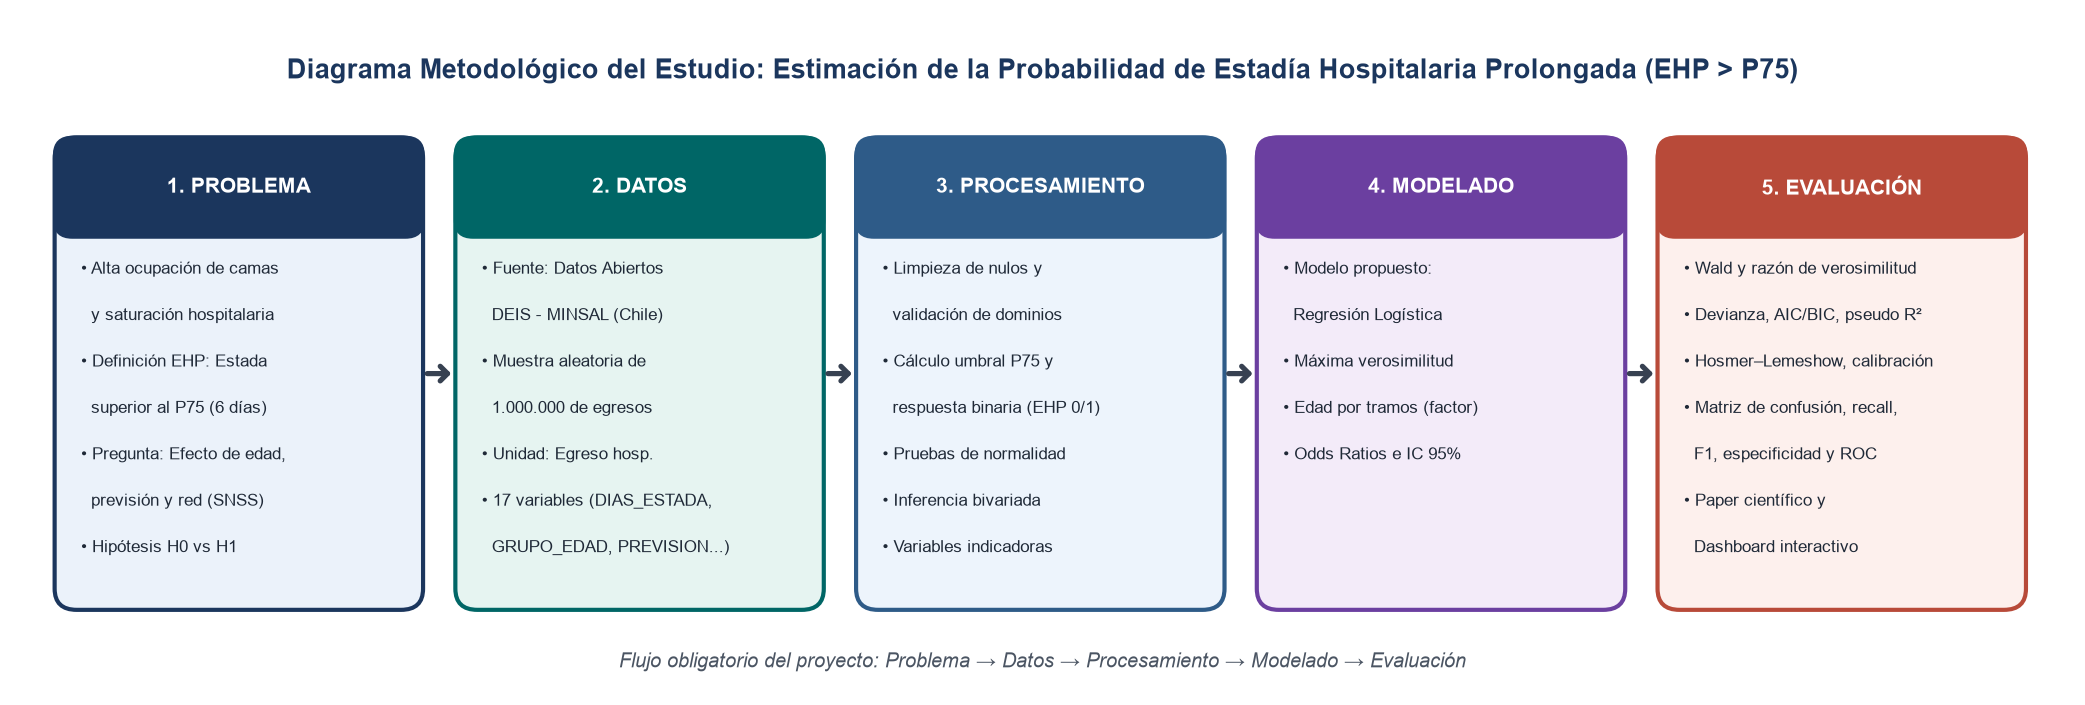

In [7]:
# Generación visual del Diagrama Metodológico: Problema -> Datos -> Procesamiento -> Modelado -> Evaluación
fig, ax = plt.subplots(figsize=(14, 4.8), dpi=150)
ax.set_xlim(0, 14)
ax.set_ylim(0, 4.8)
ax.axis('off')

ax.text(7, 4.4, "Diagrama Metodológico del Estudio: Estimación de la Probabilidad de Estadía Hospitalaria Prolongada (EHP > P75)",
        ha='center', va='center', fontsize=13, fontweight='bold', color='#1B365D')

stages = [
    {
        "title": "1. PROBLEMA",
        "color": "#1B365D",
        "bg": "#EBF2FA",
        "items": [
            "• Alta ocupación de camas",
            "  y saturación hospitalaria",
            "• Definición EHP: Estada",
            "  superior al P75 (6 días)",
            "• Pregunta: Efecto de edad,",
            "  previsión y red (SNSS)",
            "• Hipótesis H0 vs H1"
        ]
    },
    {
        "title": "2. DATOS",
        "color": "#006666",
        "bg": "#E6F4F1",
        "items": [
            "• Fuente: Datos Abiertos",
            "  DEIS - MINSAL (Chile)",
            "• Muestra aleatoria de",
            "  1.000.000 de egresos",
            "• Unidad: Egreso hosp.",
            "• 17 variables (DIAS_ESTADA,",
            "  GRUPO_EDAD, PREVISION...)"
        ]
    },
    {
        "title": "3. PROCESAMIENTO",
        "color": "#2E5B88",
        "bg": "#EDF4FC",
        "items": [
            "• Limpieza de nulos y",
            "  validación de dominios",
            "• Cálculo umbral P75 y",
            "  respuesta binaria (EHP 0/1)",
            "• Pruebas de normalidad",
            "• Inferencia bivariada",
            "• Variables indicadoras"
        ]
    },
    {
        "title": "4. MODELADO",
        "color": "#6B3FA0",
        "bg": "#F3EBF9",
        "items": [
            "• Modelo propuesto:",
            "  Regresión Logística",
            "• Máxima verosimilitud",
            "• Edad por tramos (factor)",
            "• Odds Ratios e IC 95%"
        ]
    },
    {
        "title": "5. EVALUACIÓN",
        "color": "#B84A39",
        "bg": "#FDF0ED",
        "items": [
            "• Wald y razón de verosimilitud",
            "• Devianza, AIC/BIC, pseudo R²",
            "• Hosmer–Lemeshow, calibración",
            "• Matriz de confusión, recall,",
            "  F1, especificidad y ROC",
            "• Paper científico y",
            "  Dashboard interactivo"
        ]
    }
]

box_w, box_h, start_x, gap, y_bottom = 2.35, 3.2, 0.35, 0.38, 0.65

for i, st in enumerate(stages):
    x = start_x + i * (box_w + gap)
    rect = mpatches.FancyBboxPatch((x, y_bottom), box_w, box_h,
                                   boxstyle="round,pad=0.08,rounding_size=0.15",
                                   linewidth=2, edgecolor=st["color"], facecolor=st["bg"])
    ax.add_patch(rect)
    header_h = 0.55
    header = mpatches.FancyBboxPatch((x, y_bottom + box_h - header_h), box_w, header_h,
                                     boxstyle="round,pad=0.08,rounding_size=0.12",
                                     linewidth=1.5, edgecolor=st["color"], facecolor=st["color"])
    ax.add_patch(header)
    ax.text(x + box_w / 2, y_bottom + box_h - header_h / 2, st["title"],
            ha='center', va='center', fontsize=10, fontweight='bold', color='white')
    text_y = y_bottom + box_h - header_h - 0.25
    for line in st["items"]:
        ax.text(x + 0.1, text_y, line, ha='left', va='top', fontsize=8.3, color='#1F2937')
        text_y -= 0.33
    if i < len(stages) - 1:
        ax.annotate('', xy=(x + box_w + gap - 0.08, y_bottom + box_h / 2),
                    xytext=(x + box_w + 0.08, y_bottom + box_h / 2),
                    arrowprops=dict(arrowstyle="->,head_width=0.35,head_length=0.35", lw=2.5, color='#374151'))

ax.text(7, 0.2, "Flujo obligatorio del proyecto: Problema → Datos → Procesamiento → Modelado → Evaluación",
        ha='center', va='center', fontsize=9.5, style='italic', color='#4B5563')
plt.tight_layout()
plt.show()

## 5. Análisis de Relaciones entre Variables

Esta sección desarrolla la base inferencial del estudio. En conformidad con la pauta metodológica, antes de aplicar pruebas de asociación o comparación de grupos se verifica formalmente el **supuesto de normalidad** sobre las variables numéricas, reportando para cada prueba:
* **Hipótesis Nula ($H_0$) e Hipótesis Alternativa ($H_1$)** explícitamente formuladas.
* **Estadístico de prueba** y **grados de libertad / tamaño muestral**.
* **Valor-$p$ ($p$-value)** y **nivel de significancia ($\alpha = 0.05$)**.
* **Decisión estadística** (Rechazar o No rechazar $H_0$) e **interpretación clínica y de gestión en el contexto del problema**.

Dado el tamaño de la muestra ($N = 1.000.000$), casi cualquier diferencia resulta estadísticamente significativa. Por ello, además del valor-$p$ y la decisión, se reporta el **tamaño del efecto**, que permite interpretar la relevancia de cada relación. Como guía orientativa, $r_{rb}$, $\rho$ y $V$ (con una dimensión mínima de 2) se leen como pequeños desde $0.1$, moderados desde $0.3$ y grandes desde $0.5$; $\varepsilon^2$, como pequeño desde $0.01$, moderado desde $0.06$ y grande desde $0.14$.

---
### 5.0 Carga y Preparación de la Base de Datos de Egresos Hospitalarios
En la siguiente celda se carga el archivo de microdatos `EGR_DATOS_ABIERTO_2025.csv` y se construyen las variables analíticas requeridas:
1. **`ESTADIA_PROLONGADA` (Categórica Binaria):** Toma el valor `'Prolongada (> 6d)'` (o `1` en `ESTADIA_PROLONGADA_BIN`) cuando `DIAS_ESTADA` supera estrictamente el percentil 75 ($P_{75} = 6.00\text{ días}$), y `'Normal (<= 6d)'` (o `0`) en caso contrario.
2. **`EDAD_APROX` (Numérica):** Marca de clase (punto medio en años) extraída automáticamente del tramo etario `GRUPO_EDAD` (p. ej., `'70 a 79'` $\rightarrow 74.5$ años), que se usa en el gráfico de dispersión de la sección 5.2 y para ordenar cronológicamente los tramos. Es una aproximación, porque la base registra la edad por tramos y no en años exactos.

In [8]:
# ==============================================================================
# 5.0 CARGA DE LA BASE DE DATOS DE EGRESOS HOSPITALARIOS Y PREPARACIÓN DE VARIABLES
# ==============================================================================

import pandas as pd
import numpy as np
import os
import re

RUTA_ARCHIVO_EGRESOS = "EGR_DATOS_ABIERTO_2025.csv"
if not os.path.exists(RUTA_ARCHIVO_EGRESOS):
    raise FileNotFoundError(f"No se encontró '{RUTA_ARCHIVO_EGRESOS}'. Súbelo a Colab.")

# 1. Lectura de la base completa
df = pd.read_csv(RUTA_ARCHIVO_EGRESOS, sep=";", encoding="utf-8", low_memory=False)
df.columns = [c.strip().upper() for c in df.columns]
n0 = len(df)

# Etiquetas de edad: el archivo original trae un carácter inválido en dos tramos
df["GRUPO_EDAD"] = df["GRUPO_EDAD"].replace({"menor de un a\ufffdo": "menor de un año", "90 y m\ufffds": "90 y más"})

# 2. Limpieza
df["DIAS_ESTADA"] = pd.to_numeric(df["DIAS_ESTADA"], errors="coerce")
df = df.dropna(subset=["DIAS_ESTADA", "GRUPO_EDAD", "GLOSA_PREVISION",
                       "PERTENENCIA_ESTABLECIMIENTO_SALU"])
df = df[df["DIAS_ESTADA"] > 0]
df = df[(df["GRUPO_EDAD"] != "*") &
        (~df["GLOSA_PREVISION"].isin(["*", "DESCONOCIDO"]))]
n1 = len(df)

# 3. Umbral EHP (P75) calculado sobre toda la base limpia
p75_estadia = np.percentile(df["DIAS_ESTADA"], 75)

# 4. Muestra aleatoria reproducible de 1.000.000 de egresos
df = df.sample(n=1_000_000, random_state=42).reset_index(drop=True)

# 5. Variable respuesta
df["ESTADIA_PROLONGADA_BIN"] = (df["DIAS_ESTADA"] > p75_estadia).astype(int)
df["ESTADIA_PROLONGADA"] = np.where(df["DIAS_ESTADA"] > p75_estadia,
                                    f"Prolongada (> {p75_estadia:.0f}d)",
                                    f"Normal (<= {p75_estadia:.0f}d)")

# 6. Edad aproximada (marca de clase del tramo)
def extraer_marca_edad(valor):
    s = str(valor).lower()
    if "menor" in s:
        return 0.5
    nums = [int(n) for n in re.findall(r"\d+", s)]
    if len(nums) >= 2:
        return (nums[0] + nums[1]) / 2.0
    elif len(nums) == 1:
        return float(nums[0]) + 5.0
    return np.nan

df["EDAD_APROX"] = df["GRUPO_EDAD"].apply(extraer_marca_edad)

# 7. Resumen
print("=" * 75)
print("RESUMEN DEL DATASET CARGADO")
print("=" * 75)
print(f"Registros en la base original      : {n0:,}")
print(f"Tras limpieza (sin '*'/desconocido): {n1:,}")
print(f"Muestra aleatoria analizada (N)    : {len(df):,}")
print(f"Media de DIAS_ESTADA               : {df['DIAS_ESTADA'].mean():.2f} días")
print(f"Mediana de DIAS_ESTADA             : {df['DIAS_ESTADA'].median():.2f} días")
print(f"Percentil 75 (umbral EHP)          : {p75_estadia:.2f} días")
print(f"Desviación estándar                : {df['DIAS_ESTADA'].std():.2f} días")
print(f"Asimetría (skewness)               : {df['DIAS_ESTADA'].skew():.2f}")
print(f"Proporción estadía prolongada      : {df['ESTADIA_PROLONGADA_BIN'].mean()*100:.2f}%")

RESUMEN DEL DATASET CARGADO
Registros en la base original      : 1,705,514
Tras limpieza (sin '*'/desconocido): 1,576,792
Muestra aleatoria analizada (N)    : 1,000,000
Media de DIAS_ESTADA               : 6.13 días
Mediana de DIAS_ESTADA             : 2.00 días
Percentil 75 (umbral EHP)          : 6.00 días
Desviación estándar                : 40.48 días
Asimetría (skewness)               : 198.13
Proporción estadía prolongada      : 21.65%


---
### 5.1 Pruebas de Bondad de Ajuste (Supuesto de Normalidad)

Antes de seleccionar pruebas paramétricas o no paramétricas para las secciones siguientes, se evalúa si la variable numérica del estudio, los días de hospitalización (`DIAS_ESTADA`), sigue una distribución Normal $N(\mu, \sigma^2)$. Según la pauta, este resultado determina si en las secciones 5.2 y 5.3 se usan pruebas paramétricas o no paramétricas. La edad no se evalúa, porque la base la registra en tramos (variable ordinal).

#### Formulación de Hipótesis ($\alpha = 0.05$)
* **Hipótesis Nula ($H_0$):** La variable proviene de una población con distribución Normal: $X \sim N(\mu, \sigma^2)$.
* **Hipótesis Alternativa ($H_1$):** La variable **no** sigue una distribución Normal: $X \nsim N(\mu, \sigma^2)$.
* **Regla de decisión:** Si $\text{valor-}p < \alpha = 0.05$ (o si el estadístico de Anderson–Darling supera el valor crítico al $5\%$), se rechaza $H_0$.

#### Pruebas Aplicadas y Justificación Metodológica
1. **Prueba de Shapiro–Wilk (`scipy.stats.shapiro`):** Es el test más potente para contrastar normalidad en muestras pequeñas y medianas ($n \le 5.000$). Dado que la muestra analizada cuenta con $1.000.000$ de registros y en tamaños masivos cualquier desviación mínima produce $p \approx 0$, las tres pruebas se aplican sobre una submuestra aleatoria simple reproducible de $n = 5.000$ observaciones (`random_state=42`).
2. **Prueba de Kolmogorov–Smirnov con corrección de Lilliefors (`lilliefors`):** Evalúa la distancia suprema $D = \sup_x |F_n(x) - F(x)|$ entre la función de distribución acumulada empírica y la normal teórica cuando la media $\hat{\mu}$ y la desviación estándar $\hat{\sigma}$ se estiman desde la propia muestra.
3. **Prueba de Anderson–Darling (`scipy.stats.anderson`):** Otorga mayor ponderación a las colas de la distribución ($A^2$), siendo especialmente sensible a la fuerte cola derecha característica de las estadías hospitalarias prolongadas (asimetría $= 198.13$).

RESULTADOS 5.1: PRUEBAS DE BONDAD DE AJUSTE (SUPUESTO DE NORMALIDAD - DIAS_ESTADA)
1) Shapiro-Wilk (n=5000)             : W  = 0.2219 | valor-p = 5.3092e-90 | Decisión: Rechazar H0 (No Normal)
2) Kolmogorov-Smirnov (Lilliefors)      : D  = 0.3881 | valor-p = 1.0000e-03 | Decisión: Rechazar H0 (No Normal)
3) Anderson-Darling                     : A² = 1063.4934 | Crítico (5%) = 0.7520 | Decisión: Rechazar H0 (No Normal)
--------------------------------------------------------------------------------
CONCLUSIÓN ETAPA 5.1: En las tres pruebas se rechaza la hipótesis nula
de normalidad (p < 0.05). Por tanto, en las secciones 5.2 y 5.3 se aplican
las pruebas NO PARAMÉTRICAS (Spearman, Mann-Whitney U y Kruskal-Wallis + Dunn).


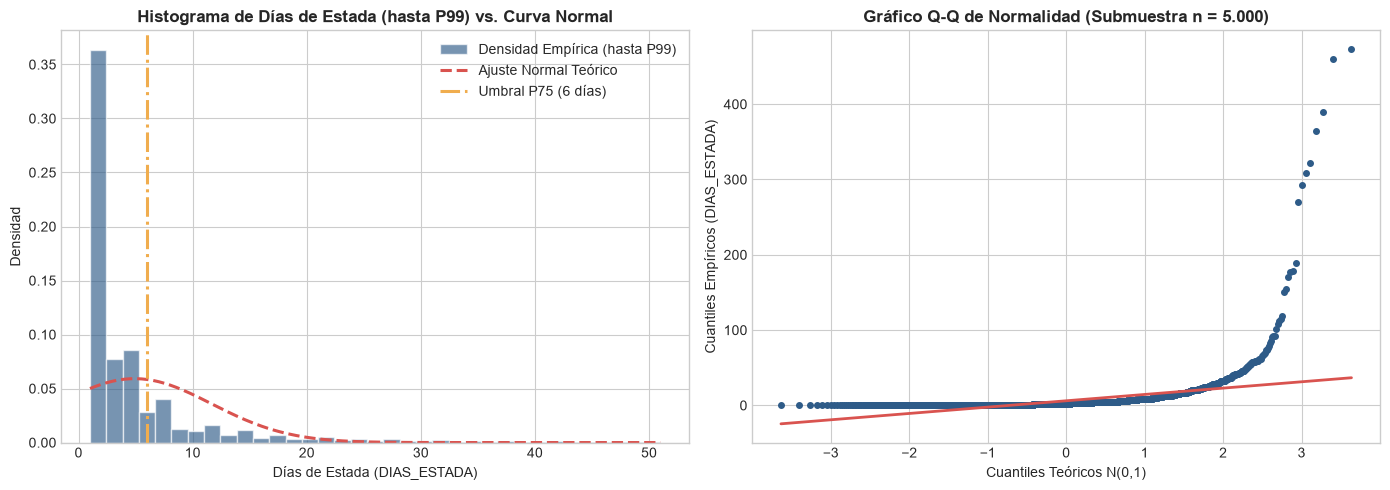

In [9]:
# ==============================================================================
# 5.1 PRUEBAS DE BONDAD DE AJUSTE (NORMALIDAD DE DIAS_ESTADA) + HISTOGRAMA Y Q-Q
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

alpha = 0.05
col_estadia = "DIAS_ESTADA" if "DIAS_ESTADA" in df.columns else "DIAS_ESTAD"
serie_estadia = df[col_estadia].dropna()
p75_estadia = np.percentile(serie_estadia, 75)

# Submuestra aleatoria reproducible n = 5000 para Shapiro-Wilk y gráficos ágiles
n_sub = min(5000, len(serie_estadia))
submuestra_estadia = serie_estadia.sample(n=n_sub, random_state=42)

# 1. Prueba de Shapiro-Wilk (sobre n <= 5000)
stat_sw, p_sw = stats.shapiro(submuestra_estadia)

# 2. Prueba de Kolmogorov-Smirnov con corrección de Lilliefors
try:
    from statsmodels.stats.diagnostic import lilliefors
    stat_ks_lill, p_ks_lill = lilliefors(submuestra_estadia, dist="norm", pvalmethod="table")
except ImportError:
    stat_ks_lill, p_ks_lill = stats.kstest(submuestra_estadia, "norm", args=(submuestra_estadia.mean(), submuestra_estadia.std(ddof=1)))

# 3. Prueba de Anderson-Darling
res_ad = stats.anderson(submuestra_estadia, dist="norm")
stat_ad = res_ad.statistic
# Nivel de significancia de 5% corresponde al índice 2 en res_ad.significance_level ([15., 10., 5., 2.5, 1.])
crit_ad_5pct = res_ad.critical_values[2]

print("=" * 80)
print(f"RESULTADOS 5.1: PRUEBAS DE BONDAD DE AJUSTE (SUPUESTO DE NORMALIDAD - {col_estadia})")
print("=" * 80)
print(f"1) Shapiro-Wilk (n={n_sub})             : W  = {stat_sw:.4f} | valor-p = {p_sw:.4e} | "
      f"Decisión: {'Rechazar H0 (No Normal)' if p_sw < alpha else 'No rechazar H0'}")
print(f"2) Kolmogorov-Smirnov (Lilliefors)      : D  = {stat_ks_lill:.4f} | valor-p = {p_ks_lill:.4e} | "
      f"Decisión: {'Rechazar H0 (No Normal)' if p_ks_lill < alpha else 'No rechazar H0'}")
print(f"3) Anderson-Darling                     : A² = {stat_ad:.4f} | Crítico (5%) = {crit_ad_5pct:.4f} | "
      f"Decisión: {'Rechazar H0 (No Normal)' if stat_ad > crit_ad_5pct else 'No rechazar H0'}")
print("-" * 80)
print("CONCLUSIÓN ETAPA 5.1: En las tres pruebas se rechaza la hipótesis nula")
print("de normalidad (p < 0.05). Por tanto, en las secciones 5.2 y 5.3 se aplican")
print("las pruebas NO PARAMÉTRICAS (Spearman, Mann-Whitney U y Kruskal-Wallis + Dunn).")

# Visualización rápida y limpia: Histograma (acotado al P99) y Gráfico Q-Q
p99_vis = np.percentile(serie_estadia, 99)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Histograma de densidad vs Curva Normal Teórica
datos_vis = serie_estadia[serie_estadia <= p99_vis]
ax1.hist(datos_vis, bins=35, density=True, color="#2E5B88", alpha=0.65,
         edgecolor="white", label="Densidad Empírica (hasta P99)")
x_grid = np.linspace(datos_vis.min(), datos_vis.max(), 200)
ax1.plot(x_grid, stats.norm.pdf(x_grid, datos_vis.mean(), datos_vis.std()),
         color="#D9534F", lw=2.2, linestyle="--", label="Ajuste Normal Teórico")
ax1.axvline(p75_estadia, color="#F0AD4E", lw=2.2, linestyle="-.",
            label=f"Umbral P75 ({p75_estadia:.0f} días)")
ax1.set_title("Histograma de Días de Estada (hasta P99) vs. Curva Normal", fontweight="bold")
ax1.set_xlabel("Días de Estada (DIAS_ESTADA)")
ax1.set_ylabel("Densidad")
ax1.legend()

# Gráfico Q-Q (Quantile-Quantile)
stats.probplot(submuestra_estadia, dist="norm", plot=ax2)
ax2.get_lines()[0].set_color("#2E5B88")
ax2.get_lines()[0].set_markersize(4.0)
ax2.get_lines()[1].set_color("#D9534F")
ax2.get_lines()[1].set_linewidth(2.0)
ax2.set_title("Gráfico Q-Q de Normalidad (Submuestra n = 5.000)", fontweight="bold")
ax2.set_xlabel("Cuantiles Teóricos N(0,1)")
ax2.set_ylabel("Cuantiles Empíricos (DIAS_ESTADA)")

plt.tight_layout()
plt.show()


#### Interpretación Clínica y Metodológica
* **Decisión estadística:** Con un nivel de significancia $\alpha = 0.05$, tanto la prueba de **Shapiro–Wilk** ($W = 0.222$, $p < 0.0001$), como **Kolmogorov–Smirnov con corrección de Lilliefors** ($D = 0.388$, $p \le 0.001$, cota inferior de la tabla de Lilliefors) y **Anderson–Darling** ($A^2 \gg A^2_{\text{crítico } 5\%}$) conducen a **rechazar la hipótesis nula ($H_0$) de normalidad**.
* **Análisis visual:** El histograma confirma una distribución fuertemente **asimétrica hacia la derecha (sesgo positivo $= 198.13$)** donde la mediana ($2.00\text{ días}$) es muy inferior a la media ($6.13\text{ días}$): la mayoría de las hospitalizaciones duran entre 1 y 6 días ($P_{75} = 6.00\text{ días}$), mientras que existe una cola derecha extensa compuesta por pacientes crónicos complejos, hospitalizaciones en unidades críticas y casos de "hospitalización social". En consecuencia, el **gráfico Q-Q** muestra una severa desviación respecto a la recta diagonal teórica.
* **Implicancia metodológica para las etapas 5.2 y 5.3:** Como no se cumple la normalidad, y según indica la pauta, en las secciones **5.2** y **5.3** se aplican las **pruebas no paramétricas basadas en rangos**: Spearman en lugar de Pearson, Mann–Whitney U en lugar de la $t$ de Student, y Kruskal–Wallis con post-hoc de Dunn en lugar del ANOVA de un factor con Tukey HSD.

---
### 5.2 Relación Numérica vs. Numérica: edad vs. `DIAS_ESTADA`

Para evaluar cómo se relaciona la edad del paciente con la duración de la hospitalización (`DIAS_ESTADA`) se usa la correlación de **Spearman ($\rho$)**, porque en la etapa 5.1 se rechazó la normalidad y Pearson la requiere. Como la base registra la edad por tramos, Spearman se calcula sobre el orden natural de `GRUPO_EDAD`. El gráfico de dispersión usa `EDAD_APROX`, el punto medio de cada tramo, solo para ubicar los puntos en el eje horizontal.

#### Formulación de Hipótesis ($\alpha = 0.05$)
* **Correlación de Spearman ($\rho$):**
  * $H_0: \rho = 0$ (No existe asociación monótona entre la edad del paciente y los días de estada hospitalaria).
  * $H_1: \rho \neq 0$ (Existe una asociación monótona estadísticamente significativa entre la edad y los días de estada).


RESULTADOS 5.2: RELACIÓN NUMÉRICA VS. NUMÉRICA (EDAD vs. DIAS_ESTADA)
Tamaño muestral evaluado (N) : 1,000,000
Spearman (orden de tramos)   : rho = 0.1910 | valor-p = 0.0000e+00 | Decisión: Rechazar H0
Tamaño del efecto            : rho² = 0.0365
Comprobación                 : Spearman con la marca de clase, rho = 0.1910
Interpretación               : Relación positiva (directa) de magnitud pequeña.


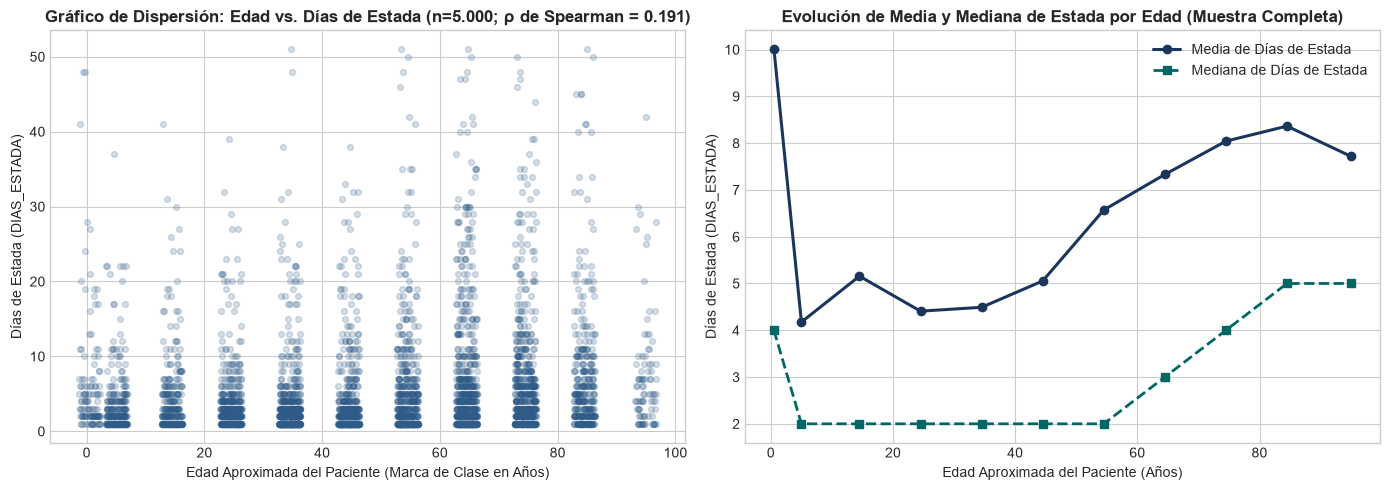

In [10]:
# ==============================================================================
# 5.2 NUMÉRICA VS. NUMÉRICA: EDAD VS. DIAS_ESTADA (SPEARMAN)
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

alpha = 0.05
col_estadia = "DIAS_ESTADA" if "DIAS_ESTADA" in df.columns else "DIAS_ESTAD"
df_num = df[["GRUPO_EDAD", "EDAD_APROX", col_estadia]].dropna()
p99_vis = np.percentile(df_num[col_estadia], 99)

# Correlación de Spearman (rho) sobre el orden natural de los tramos de GRUPO_EDAD
orden_tramos = df_num.groupby("GRUPO_EDAD")["EDAD_APROX"].mean().sort_values().index
orden_ordinal = df_num["GRUPO_EDAD"].map({t: i for i, t in enumerate(orden_tramos, start=1)})
rho_spearman, p_spearman = stats.spearmanr(orden_ordinal, df_num[col_estadia])
# Comprobación: Spearman solo usa el orden, por lo que la marca de clase da el mismo resultado
rho_marca, _ = stats.spearmanr(df_num["EDAD_APROX"], df_num[col_estadia])

def clasificar_fuerza(coef):
    c = abs(coef)
    if c < 0.10:
        return "muy débil / marginal"
    elif c < 0.30:
        return "pequeña"
    elif c < 0.50:
        return "moderada"
    else:
        return "fuerte"

direccion = "positiva (directa)" if rho_spearman > 0 else "negativa (inversa)"

print("=" * 80)
print(f"RESULTADOS 5.2: RELACIÓN NUMÉRICA VS. NUMÉRICA (EDAD vs. {col_estadia})")
print("=" * 80)
print(f"Tamaño muestral evaluado (N) : {len(df_num):,}")
print(f"Spearman (orden de tramos)   : rho = {rho_spearman:.4f} | valor-p = {p_spearman:.4e} | "
      f"Decisión: {'Rechazar H0' if p_spearman < alpha else 'No rechazar H0'}")
print(f"Tamaño del efecto            : rho² = {rho_spearman**2:.4f}")
print(f"Comprobación                 : Spearman con la marca de clase, rho = {rho_marca:.4f}")
print(f"Interpretación               : Relación {direccion} de magnitud {clasificar_fuerza(rho_spearman)}.")

# Visualización: Gráfico de dispersión (muestra n=5000 para evitar saturación visual) + Media por edad
df_num_vis = df_num[df_num[col_estadia] <= p99_vis]
muestra_scatter = df_num_vis.sample(n=min(5000, len(df_num_vis)), random_state=42)
resumen_edad = df_num.groupby("EDAD_APROX")[col_estadia].agg(["mean", "median", "count"]).reset_index()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Panel A: Dispersión con jitter horizontal (sin recta: la relación evaluada es monótona, no lineal)
rng = np.random.default_rng(42)
jitter = rng.uniform(-1.8, 1.8, len(muestra_scatter))
ax1.scatter(muestra_scatter["EDAD_APROX"] + jitter, muestra_scatter[col_estadia],
            alpha=0.2, color="#2E5B88", s=18)
ax1.set_title(f"Gráfico de Dispersión: Edad vs. Días de Estada (n=5.000; ρ de Spearman = {rho_spearman:.3f})",
              fontweight="bold")
ax1.set_xlabel("Edad Aproximada del Paciente (Marca de Clase en Años)")
ax1.set_ylabel("Días de Estada (DIAS_ESTADA)")

# Panel B: Curva de Media y Mediana de Días de Estada según Edad en toda la población
ax2.plot(resumen_edad["EDAD_APROX"], resumen_edad["mean"], marker="o", lw=2.2,
         color="#1B365D", label="Media de Días de Estada")
ax2.plot(resumen_edad["EDAD_APROX"], resumen_edad["median"], marker="s", lw=2.0, linestyle="--",
         color="#006666", label="Mediana de Días de Estada")
ax2.set_title("Evolución de Media y Mediana de Estada por Edad (Muestra Completa)", fontweight="bold")
ax2.set_xlabel("Edad Aproximada del Paciente (Años)")
ax2.set_ylabel("Días de Estada (DIAS_ESTADA)")
ax2.legend()

plt.tight_layout()
plt.show()

#### Interpretación Clínica y Metodológica
* **Decisión estadística:** Con $\alpha = 0.05$, se **rechaza la hipótesis nula ($H_0$)** de la correlación de **Spearman** ($\rho = 0.191$, $p < 0.0001$), calculada sobre el orden de los tramos de edad; el resultado es idéntico con la marca de clase, porque esta conserva ese orden.
* **Dirección y fuerza de la relación:** Se observa una asociación **positiva (directa)** global y estadísticamente significativa entre la edad y los días de hospitalización. Si bien a nivel individual el coeficiente es de magnitud pequeña ($\rho^2 = 0.037$; producto de la alta variabilidad diagnóstica dentro de cada tramo etario), el gráfico de medias y medianas por tramo etario confirma que a partir de los 50 años la duración de la hospitalización crece de manera sostenida (media de $6.57$ días en 50–59 a $8.36$ días en 80–89; mediana de $2$ a $5$ días). La excepción son los **menores de un año**, que registran la media más alta de toda la cohorte ($10.01$ días; mediana $4$ días), lo que explica en parte la magnitud pequeña del coeficiente, validando la inclusión de la edad en el modelo multivariado del Avance 2.

---
### 5.3 Relación Numérica vs. Categórica

Siguiendo la pauta del Avance 1, se evalúa el comportamiento de la variable numérica `DIAS_ESTADA` a través de factores categóricos en dos escenarios. Como en la etapa 5.1 se rechazó la normalidad, se aplican las pruebas no paramétricas que indica la pauta:
1. **Comparación entre dos grupos (5.3.A):** `DIAS_ESTADA` según `PERTENENCIA_ESTABLECIMIENTO_SALU` (Establecimientos **Pertenecientes al SNSS** vs. **No Pertenecientes al SNSS**), mediante la prueba **U de Mann–Whitney**.
2. **Comparación entre tres o más grupos (5.3.B):** `DIAS_ESTADA` según `GLOSA_PREVISION` (sistema previsional de salud) y según `GRUPO_EDAD`, mediante la prueba **H de Kruskal–Wallis** y, si resulta significativa, el post-hoc de **Dunn** con corrección de Bonferroni.

En ambos casos se aplica además la **prueba de Levene**, que compara la dispersión de los grupos. Si la dispersión difiere, las distribuciones no tienen la misma forma, y las pruebas de rangos no pueden leerse como una comparación de medianas: contrastan si un grupo tiende a tener estadías más largas que otro. Por eso las hipótesis se formulan en esos términos. El tamaño del efecto se informa con $r_{rb}$ en Mann–Whitney U y Dunn, y con $\varepsilon^2 = H/(N-1)$ en Kruskal–Wallis.

#### Formulación de Hipótesis ($\alpha = 0.05$)
* **Dos grupos (`DIAS_ESTADA` según `PERTENENCIA_ESTABLECIMIENTO_SALU`):**
  * *Prueba de Levene (dispersión):* $H_0: \sigma^2_{\text{SNSS}} = \sigma^2_{\text{No SNSS}}$ vs. $H_1: \sigma^2_{\text{SNSS}} \neq \sigma^2_{\text{No SNSS}}$.
  * *Prueba U de Mann–Whitney:* sean $X$ la estadía de un egreso SNSS e $Y$ la de un egreso no SNSS, elegidos al azar.
    * $H_0: P(X > Y) = P(Y > X)$. Ninguno de los dos tipos de establecimiento tiende a tener estadías más largas.
    * $H_1: P(X > Y) \neq P(Y > X)$. Uno de los dos tipos de establecimiento tiende a tener estadías más largas.
    * $H_0$ equivale a una probabilidad de superioridad de $0.5$, contando los empates como medio caso.
* **Tres o más grupos (`DIAS_ESTADA` según `GLOSA_PREVISION` y según `GRUPO_EDAD`):**
  * *Prueba de Levene (dispersión):* $H_0: \sigma^2_1 = \sigma^2_2 = \dots = \sigma^2_k$ vs. $H_1:$ al menos un grupo tiene una varianza distinta.
  * *Prueba H de Kruskal–Wallis:*
    * $H_0:$ `DIAS_ESTADA` tiene la misma distribución en todos los grupos, de modo que ningún grupo tiende a tener estadías más largas que otro.
    * $H_1:$ al menos un grupo tiende a tener estadías más largas o más cortas que otro.


RESULTADOS 5.3.A: DOS GRUPOS (DIAS_ESTADA por PERTENENCIA_ESTABLECIMIENTO_SALU)
Grupo 1: Perteneciente al SNSS (n=615,878, Media=7.65, Mediana=3.0)
Grupo 2: No Perteneciente al SNSS (n=384,122, Media=3.70, Mediana=1.0)
--------------------------------------------------------------------------------
1) Prueba de Levene (Varianzas) : W = 1436.7955 | valor-p = 0.0000e+00 -> Varianzas distintas: las distribuciones no tienen la misma forma
2) Mann-Whitney U               : U = 1.6858e+11 | valor-p = 0.0000e+00 | Decisión: Rechazar H0
   Tamaño del efecto          : r_rb = 0.425 | Prob. de superioridad = 0.713

RESULTADOS 5.3.B: TRES O MÁS GRUPOS (DIAS_ESTADA por GLOSA_PREVISION)
--------------------------------------------------------------------------------
                  count  mean  median    std
GLOSA_PREVISION                             
CAPREDENA          7226  6.38     3.0  36.81
DIPRECA            8597  5.95     2.0  40.58
FONASA           795208  6.78     3.0  44.17
ISAPRE     

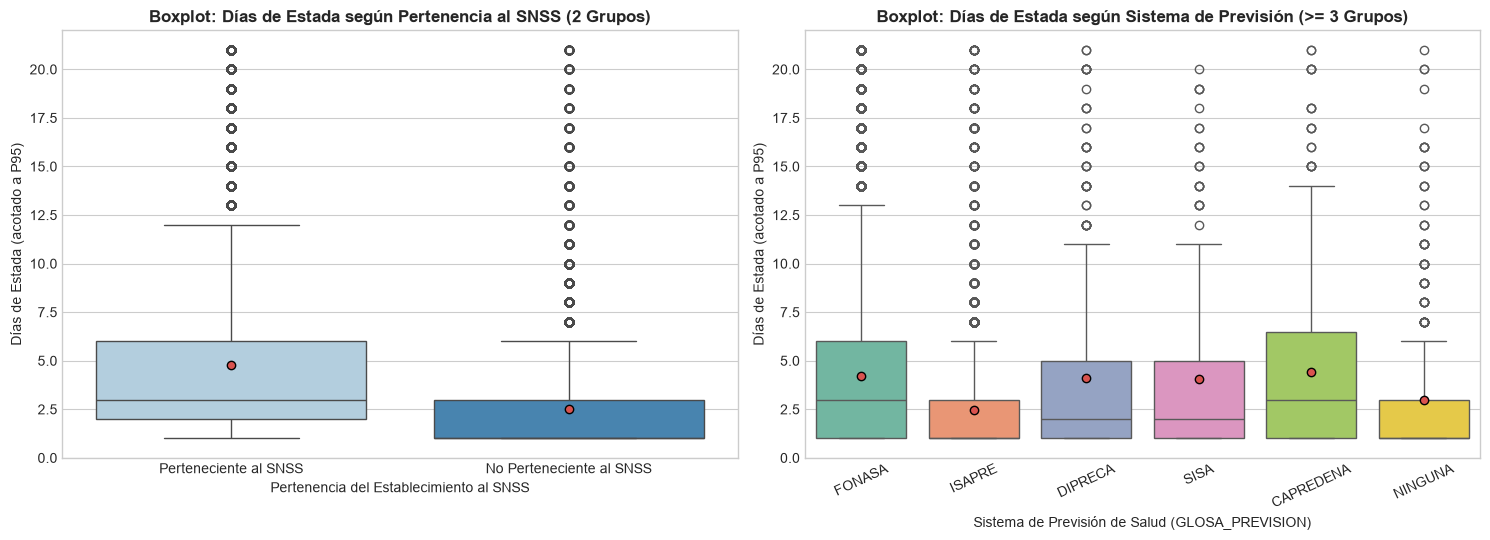

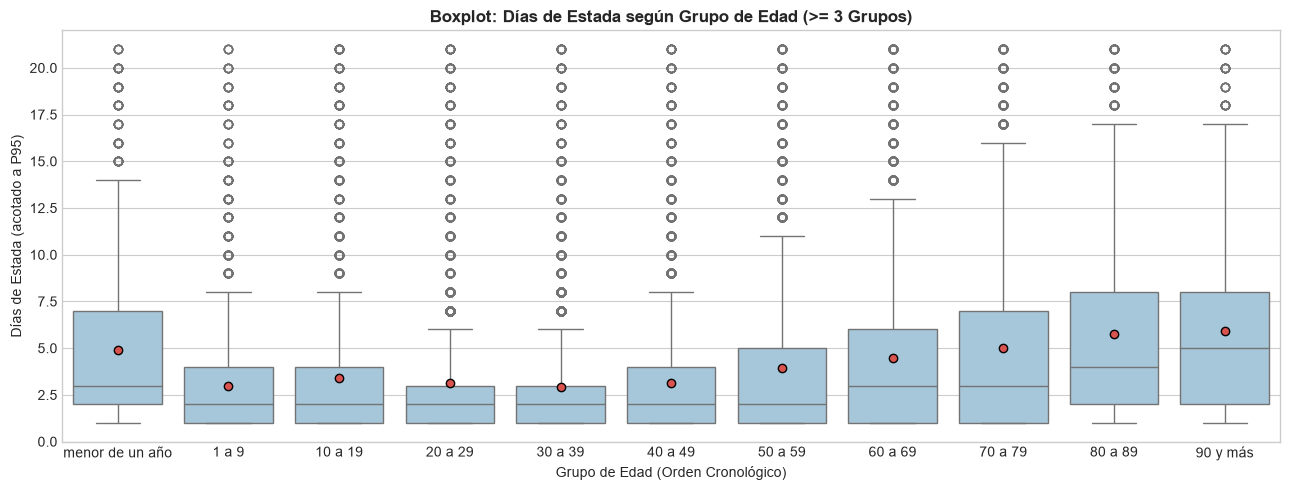

In [11]:
# ==============================================================================
# 5.3.A NUMÉRICA VS. CATEGÓRICA (2 GRUPOS): DIAS_ESTADA SEGÚN PERTENENCIA AL SNSS
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

alpha = 0.05
col_estadia = "DIAS_ESTADA" if "DIAS_ESTADA" in df.columns else "DIAS_ESTAD"

# Crear etiqueta corta legible para gráficos de PERTENENCIA_ESTABLECIMIENTO_SALU
df["RED_SNSS"] = np.where(
    df["PERTENENCIA_ESTABLECIMIENTO_SALU"].astype(str).str.lower().str.startswith("no"),
    "No Perteneciente al SNSS",
    "Perteneciente al SNSS"
)

top2_snss = ["Perteneciente al SNSS", "No Perteneciente al SNSS"]
df_snss = df[df["RED_SNSS"].isin(top2_snss)].copy()
g1_snss = df_snss[df_snss["RED_SNSS"] == top2_snss[0]][col_estadia].dropna().values
g2_snss = df_snss[df_snss["RED_SNSS"] == top2_snss[1]][col_estadia].dropna().values

# 1. Prueba de Levene (dispersión de los grupos)
stat_levene, p_levene = stats.levene(g1_snss, g2_snss, center="median")

# 2. Prueba no paramétrica: Mann-Whitney U
stat_mwu, p_mwu = stats.mannwhitneyu(g1_snss, g2_snss, alternative="two-sided")

# Tamaño del efecto: probabilidad de superioridad y correlación biserial de rangos
prob_sup_snss = stat_mwu / (len(g1_snss) * len(g2_snss))
r_rb_snss = 2 * prob_sup_snss - 1

print("=" * 80)
print(f"RESULTADOS 5.3.A: DOS GRUPOS ({col_estadia} por PERTENENCIA_ESTABLECIMIENTO_SALU)")
print(f"Grupo 1: {top2_snss[0]} (n={len(g1_snss):,}, Media={g1_snss.mean():.2f}, Mediana={np.median(g1_snss):.1f})")
print(f"Grupo 2: {top2_snss[1]} (n={len(g2_snss):,}, Media={g2_snss.mean():.2f}, Mediana={np.median(g2_snss):.1f})")
print("-" * 80)
print(f"1) Prueba de Levene (Varianzas) : W = {stat_levene:.4f} | valor-p = {p_levene:.4e} -> "
      f"{'Varianzas distintas: las distribuciones no tienen la misma forma' if p_levene < alpha else 'Varianzas homogéneas'}")
print(f"2) Mann-Whitney U               : U = {stat_mwu:.4e} | valor-p = {p_mwu:.4e} | "
      f"Decisión: {'Rechazar H0' if p_mwu < alpha else 'No rechazar H0'}")
print(f"   Tamaño del efecto          : r_rb = {r_rb_snss:.3f} | Prob. de superioridad = {prob_sup_snss:.3f}")

# ==============================================================================
# 5.3.B NUMÉRICA VS. CATEGÓRICA (>= 3 GRUPOS): DIAS_ESTADA SEGÚN GLOSA_PREVISION
# ==============================================================================
conteo_prev = df["GLOSA_PREVISION"].value_counts()
cats_prev = conteo_prev[conteo_prev >= 100].index.tolist()
df_prev = df[df["GLOSA_PREVISION"].isin(cats_prev)].copy()
listas_prev = [g[col_estadia].dropna().values for _, g in df_prev.groupby("GLOSA_PREVISION")]

# 1. Prueba de Levene (dispersión de los grupos)
stat_lev_prev, p_lev_prev = stats.levene(*listas_prev, center="median")

# 2. Kruskal-Wallis
stat_kw_prev, p_kw_prev = stats.kruskal(*listas_prev)
eps2_prev = stat_kw_prev / (len(df_prev) - 1)   # tamaño del efecto

print("\n" + "=" * 80)
print(f"RESULTADOS 5.3.B: TRES O MÁS GRUPOS ({col_estadia} por GLOSA_PREVISION)")
print("-" * 80)
print(df_prev.groupby("GLOSA_PREVISION")[col_estadia].agg(["count", "mean", "median", "std"]).round(2))
print("-" * 80)
print(f"1) Prueba de Levene (Varianzas) : W = {stat_lev_prev:.4f} | valor-p = {p_lev_prev:.4e} | "
      f"Decisión: {'Rechazar H0' if p_lev_prev < alpha else 'No rechazar H0'}")
print(f"2) Kruskal-Wallis               : H = {stat_kw_prev:.4f} | valor-p = {p_kw_prev:.4e} | "
      f"Decisión: {'Rechazar H0' if p_kw_prev < alpha else 'No rechazar H0'}")
print(f"   Tamaño del efecto          : ε² = {eps2_prev:.4f}")

# También evaluamos Levene y Kruskal-Wallis para GRUPO_EDAD (>= 3 grupos)
listas_edad = [g[col_estadia].dropna().values for _, g in df.groupby("GRUPO_EDAD") if len(g) >= 30]
stat_lev_edad, p_lev_edad = stats.levene(*listas_edad, center="median")
stat_kw_edad, p_kw_edad = stats.kruskal(*listas_edad)
eps2_edad = stat_kw_edad / (len(df) - 1)   # tamaño del efecto
print("\n" + "=" * 80)
print(f"RESULTADOS ADICIONALES 5.3.B: TRES O MÁS GRUPOS ({col_estadia} por GRUPO_EDAD)")
print(f"1) Levene (GRUPO_EDAD)            : W = {stat_lev_edad:.4f} | valor-p = {p_lev_edad:.4e} | "
      f"Decisión: {'Rechazar H0' if p_lev_edad < alpha else 'No rechazar H0'}")
print(f"2) Kruskal-Wallis (GRUPO_EDAD)     : H = {stat_kw_edad:.4f} | valor-p = {p_kw_edad:.4e} | "
      f"Decisión: {'Rechazar H0' if p_kw_edad < alpha else 'No rechazar H0'}")
print(f"   Tamaño del efecto               : ε² = {eps2_edad:.4f}")

# Visualización: Boxplots por grupo (acotando eje Y al P95 para visualizar claramente las cajas e IQR)
p95_box = np.percentile(df[col_estadia], 95)
df_snss_vis = df_snss[df_snss[col_estadia] <= p95_box]
df_prev_vis = df_prev[df_prev[col_estadia] <= p95_box]
muestra_box_snss = df_snss_vis.sample(n=min(50000, len(df_snss_vis)), random_state=42)
muestra_box_prev = df_prev_vis.sample(n=min(50000, len(df_prev_vis)), random_state=42)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))

sns.boxplot(
    data=muestra_box_snss, x="RED_SNSS", y=col_estadia, hue="RED_SNSS", legend=False, palette="Blues", ax=ax1, showmeans=True,
    meanprops={"marker": "o", "markerfacecolor": "#D9534F", "markeredgecolor": "black"}
)
ax1.set_title("Boxplot: Días de Estada según Pertenencia al SNSS (2 Grupos)", fontweight="bold")
ax1.set_xlabel("Pertenencia del Establecimiento al SNSS")
ax1.set_ylabel("Días de Estada (acotado a P95)")

sns.boxplot(
    data=muestra_box_prev, x="GLOSA_PREVISION", y=col_estadia, hue="GLOSA_PREVISION", legend=False, palette="Set2", ax=ax2, showmeans=True,
    meanprops={"marker": "o", "markerfacecolor": "#D9534F", "markeredgecolor": "black"}
)
ax2.set_title("Boxplot: Días de Estada según Sistema de Previsión (>= 3 Grupos)", fontweight="bold")
ax2.set_xlabel("Sistema de Previsión de Salud (GLOSA_PREVISION)")
ax2.set_ylabel("Días de Estada (acotado a P95)")
ax2.tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

# Boxplot de días de estada por tramo de edad
orden_edad = df.groupby("GRUPO_EDAD")["EDAD_APROX"].mean().sort_values().index.tolist()
df_edad_vis = df[df[col_estadia] <= p95_box]
muestra_box_edad = df_edad_vis.sample(n=min(50000, len(df_edad_vis)), random_state=42)
fig, ax = plt.subplots(figsize=(13, 5))
sns.boxplot(
    data=muestra_box_edad, x="GRUPO_EDAD", y=col_estadia, order=orden_edad, color="#9ECAE1", ax=ax, showmeans=True,
    meanprops={"marker": "o", "markerfacecolor": "#D9534F", "markeredgecolor": "black"}
)
ax.set_title("Boxplot: Días de Estada según Grupo de Edad (>= 3 Grupos)", fontweight="bold")
ax.set_xlabel("Grupo de Edad (Orden Cronológico)")
ax.set_ylabel("Días de Estada (acotado a P95)")
plt.tight_layout()
plt.show()

#### Post-hoc no paramétrico de Dunn (`GLOSA_PREVISION`)
Como Kruskal–Wallis solo indica que al menos una previsión difiere, se aplica la **prueba de Dunn**, su post-hoc basado en rangos, con corrección de **Bonferroni** por comparaciones múltiples, sobre la misma muestra (`df_prev`).
* $H_0$ (para cada par $i, j$): las distribuciones de `DIAS_ESTADA` de ambas previsiones son iguales.
* $H_1$: las distribuciones difieren. Se rechaza $H_0$ si $p_{\text{Bonferroni}} < 0.05$.
* **Estadístico y tamaño del efecto:** para cada par se informa el estadístico $z$ de Dunn y la correlación biserial de rangos ($r_{rb}$).

In [12]:
try:
    import scikit_posthocs as sp
except ImportError:   # por ejemplo, en Colab
    get_ipython().run_line_magic("pip", "install scikit-posthocs -q")
    import scikit_posthocs as sp

# Post-hoc de Dunn (corresponde a Kruskal-Wallis), con corrección de Bonferroni
dunn_prev = sp.posthoc_dunn(df_prev, val_col="DIAS_ESTADA",
                            group_col="GLOSA_PREVISION", p_adjust="bonferroni")

print("Post-hoc de Dunn (Bonferroni) - valores p por par de previsiones")
print(dunn_prev.round(4))

# Estadístico z de Dunn y tamaño del efecto (correlación biserial de rangos) para cada par
def tabla_pares_dunn(datos, col_grupo, orden, tabla_p):
    rangos = datos[col_estadia].rank()
    medios = rangos.groupby(datos[col_grupo]).mean()
    empates = datos[col_estadia].value_counts().to_numpy(dtype="float64")
    N = len(datos)
    var_rangos = N * (N + 1) / 12 - (empates**3 - empates).sum() / (12 * (N - 1))
    grupos = {g: datos.loc[datos[col_grupo] == g, col_estadia].to_numpy() for g in orden}
    filas = []
    for i, a in enumerate(orden):
        for b in orden[i + 1:]:
            na, nb = len(grupos[a]), len(grupos[b])
            z = (medios[a] - medios[b]) / np.sqrt(var_rangos * (1 / na + 1 / nb))
            U = stats.mannwhitneyu(grupos[a], grupos[b]).statistic
            filas.append({"Grupo 1": a, "Grupo 2": b, "Rango medio 1": medios[a], "Rango medio 2": medios[b],
                          "z": z, "p_Bonferroni": tabla_p.loc[a, b], "r_rb": 2 * U / (na * nb) - 1})
    pares = pd.DataFrame(filas)
    pares["Significativo"] = pares["p_Bonferroni"] < alpha
    # Comprobación: el z calculado reproduce el valor p ajustado de scikit-posthocs
    p_calculado = np.minimum(1, 2 * stats.norm.sf(pares["z"].abs()) * len(pares))
    assert np.allclose(p_calculado, pares["p_Bonferroni"], atol=1e-6)
    return pares

orden_prev = df_prev[col_estadia].rank().groupby(df_prev["GLOSA_PREVISION"]).mean().sort_values(ascending=False).index.tolist()
pares_prev = tabla_pares_dunn(df_prev, "GLOSA_PREVISION", orden_prev, dunn_prev)
print(f"\nPares con diferencia significativa: {pares_prev['Significativo'].sum()} de {len(pares_prev)}")
display(pares_prev.round(4))

Post-hoc de Dunn (Bonferroni) - valores p por par de previsiones
           CAPREDENA  DIPRECA  FONASA  ISAPRE  NINGUNA    SISA
CAPREDENA     1.0000   0.0000  0.0021     0.0      0.0  0.0001
DIPRECA       0.0000   1.0000  0.0000     0.0      0.0  0.0487
FONASA        0.0021   0.0000  1.0000     0.0      0.0  0.0000
ISAPRE        0.0000   0.0000  0.0000     1.0      0.0  0.0000
NINGUNA       0.0000   0.0000  0.0000     0.0      1.0  0.0000
SISA          0.0001   0.0487  0.0000     0.0      0.0  1.0000

Pares con diferencia significativa: 15 de 15


,Grupo 1,Grupo 2,Rango medio 1,Rango medio 2,z,p_Bonferroni,r_rb,Significativo
0,FONASA,CAPREDENA,530091.5711,517427.1482,3.8028,0.0021,0.0225,True
1,FONASA,SISA,530091.5711,494522.3566,8.9504,0.0000,0.0718,True
2,FONASA,DIPRECA,530091.5711,479826.6813,16.4487,0.0000,0.0996,True
3,FONASA,NINGUNA,530091.5711,407341.8707,39.9182,0.0000,0.2435,True
4,FONASA,ISAPRE,530091.5711,368504.7835,217.3635,0.0000,0.3234,True
5,CAPREDENA,SISA,517427.1482,494522.3566,4.4340,0.0001,0.0459,True
6,CAPREDENA,DIPRECA,517427.1482,479826.6813,8.3599,0.0000,0.0708,True
7,CAPREDENA,NINGUNA,517427.1482,407341.8707,24.4049,0.0000,0.2097,True
8,CAPREDENA,ISAPRE,517427.1482,368504.7835,44.0222,0.0000,0.2857,True
9,SISA,DIPRECA,494522.3566,479826.6813,2.9432,0.0487,0.0296,True


#### Interpretación Clínica y Metodológica (Sección 5.3)
* **Comparación entre dos grupos (`PERTENENCIA_ESTABLECIMIENTO_SALU`):**
  * La **prueba de Levene** rechaza la igualdad de varianzas entre hospitales pertenecientes y no pertenecientes al SNSS ($W = 1436.80$, $p < 0.001$). Las dos distribuciones no tienen la misma forma, por lo que Mann–Whitney U se interpreta como una comparación de qué grupo tiende a tener estadías más largas, y no como una comparación de medianas.
  * La prueba **U de Mann–Whitney** rechaza $H_0$ ($U = 1.69 \times 10^{11}$, $p < 0.001$), con un efecto moderado ($r_{rb} = 0.425$): en el $71\%$ de los pares de egresos, el del SNSS tiene la estadía más larga, contando los empates como medio caso. Los hospitales públicos pertenecientes al SNSS presentan un rango intercuartílico más amplio y una media de estadía superior a la de los establecimientos no pertenecientes. La mayor carga de complejidad social y los tiempos de espera intrahospitalarios del sector público son posibles explicaciones, pero estas pruebas no permiten identificar el mecanismo.
* **Comparación entre tres o más grupos (`GLOSA_PREVISION` y `GRUPO_EDAD`):**
  * La prueba de **Kruskal–Wallis** rechaza $H_0$ ($p < 0.001$) tanto para la previsión como para la edad. El tamaño del efecto es pequeño para la previsión ($H = 48247.77$, $\varepsilon^2 = 0.048$) y moderado, cerca del límite inferior, para la edad ($H = 61745.92$, $\varepsilon^2 = 0.062$). Levene también rechaza la igualdad de varianzas en ambos casos (previsión: $W = 163.40$; edad: $W = 112.51$; $p < 0.001$), por lo que el resultado indica que algún grupo tiende a tener estadías más largas, no que difieran las medianas.
  * Los pacientes afiliados a **FONASA** registran la mayor estadía media ($6.78$ días; mediana $3$), seguidos de **CAPREDENA** ($6.38$) y **DIPRECA** ($5.95$), mientras que los afiliados a **ISAPRE** presentan la menor ($3.28$ días; mediana $1$). Según el post-hoc de **Dunn con corrección de Bonferroni**, que compara rangos sobre toda la muestra, **los 15 pares de previsiones difieren significativamente** ($p_{\text{Bonferroni}} < 0.05$; el par menos marcado es DIPRECA vs. SISA, $p = 0.049$). Sin embargo, solo FONASA vs. ISAPRE alcanza un efecto moderado ($r_{rb} = 0.323$), y $7$ de los $15$ pares tienen $|r_{rb}| < 0.1$: son significativos por el tamaño de la muestra, pero sus diferencias son muy pequeñas. El orden de rangos medios es FONASA > CAPREDENA > SISA > DIPRECA > NINGUNA > ISAPRE, de modo que FONASA concentra las estadías más largas e ISAPRE las más cortas. La brecha FONASA/ISAPRE es la más marcada, lo que muestra una asociación entre la segmentación previsional y la duración de la hospitalización.

#### Post-hoc no paramétrico de Dunn (`GRUPO_EDAD`)
Como Kruskal–Wallis solo indica que al menos un tramo de edad difiere, se aplica la **prueba de Dunn** con corrección de **Bonferroni** para identificar qué pares difieren.
* $H_0$ (para cada par $i, j$): las distribuciones de `DIAS_ESTADA` de ambos tramos son iguales.
* $H_1$: las distribuciones difieren. Se rechaza $H_0$ si $p_{\text{Bonferroni}} < 0.05$.

In [13]:
# Post-hoc de Dunn (corresponde a Kruskal-Wallis), con corrección de Bonferroni, por tramo de edad
dunn_edad = sp.posthoc_dunn(df, val_col=col_estadia, group_col="GRUPO_EDAD",
                            p_adjust="bonferroni").loc[orden_edad, orden_edad]
pares_edad = tabla_pares_dunn(df, "GRUPO_EDAD", orden_edad, dunn_edad)

resumen_rangos = df.groupby("GRUPO_EDAD")[col_estadia].agg(n="count", Media="mean", Mediana="median").loc[orden_edad]
resumen_rangos["Rango medio"] = df[col_estadia].rank().groupby(df["GRUPO_EDAD"]).mean().loc[orden_edad]
print("Días de estada por tramo de edad (orden cronológico):")
display(resumen_rangos.round(2))

print(f"Pares con diferencia significativa: {pares_edad['Significativo'].sum()} de {len(pares_edad)}")
print("\nPares sin diferencia significativa:")
display(pares_edad.loc[~pares_edad["Significativo"], ["Grupo 1", "Grupo 2", "z", "p_Bonferroni", "r_rb"]].round(4))

# Tramos de 60 años y más frente a los tramos menores de 60 (Grupo 1 es el más joven: r_rb < 0 si el mayor tiene estadías más largas)
mayores = ["60 a 69", "70 a 79", "80 a 89", "90 y más"]
cruce = pares_edad[pares_edad["Grupo 2"].isin(mayores) & ~pares_edad["Grupo 1"].isin(mayores)]
print(f"Comparaciones de tramos >= 60 años vs. tramos < 60 años: {len(cruce)} | Significativas: {cruce['Significativo'].sum()}")
print("Tramos >= 60 años vs. tramos < 60 años (tamaño del efecto):")
display(cruce[["Grupo 1", "Grupo 2", "Rango medio 1", "Rango medio 2", "z", "p_Bonferroni", "r_rb"]].round(4))
print("Comparaciones entre tramos >= 60 años:")
display(pares_edad[pares_edad["Grupo 1"].isin(mayores) & pares_edad["Grupo 2"].isin(mayores)]
        [["Grupo 1", "Grupo 2", "Rango medio 1", "Rango medio 2", "z", "p_Bonferroni", "r_rb"]].round(4))

Días de estada por tramo de edad (orden cronológico):


,n,Media,Mediana,Rango medio
GRUPO_EDAD,,,,
menor de un año,24521,10.01,4.0,598011.92
1 a 9,58269,4.18,2.0,428604.38
10 a 19,62585,5.16,2.0,459343.53
20 a 29,108966,4.41,2.0,458461.75
30 a 39,155823,4.49,2.0,432898.92
40 a 49,114179,5.05,2.0,431519.44
50 a 59,118518,6.57,2.0,487898.46
60 a 69,146462,7.33,3.0,539648.97
70 a 79,123670,8.04,4.0,586329.69


Pares con diferencia significativa: 51 de 55

Pares sin diferencia significativa:


,Grupo 1,Grupo 2,z,p_Bonferroni,r_rb
12,1 a 9,30 a 39,-3.1382,0.0935,-0.0105
13,1 a 9,40 a 49,-2.0317,1.0000,0.0015
19,10 a 19,20 a 29,0.6238,1.0000,-0.0089
34,30 a 39,40 a 49,1.2565,1.0000,0.0184


Comparaciones de tramos >= 60 años vs. tramos < 60 años: 28 | Significativas: 28
Tramos >= 60 años vs. tramos < 60 años (tamaño del efecto):


,Grupo 1,Grupo 2,Rango medio 1,Rango medio 2,z,p_Bonferroni,r_rb
6,menor de un año,60 a 69,598011.9209,539648.9654,30.0138,0.0,0.1100
7,menor de un año,70 a 79,598011.9209,586329.6883,5.9299,0.0,0.0173
8,menor de un año,80 a 89,598011.9209,635441.6251,-17.9341,0.0,-0.0804
9,menor de un año,90 y más,598011.9209,652387.0790,-18.9486,0.0,-0.1098
15,1 a 9,60 a 69,428604.3817,539648.9654,-80.4480,0.0,-0.2204
16,1 a 9,70 a 79,428604.3817,586329.6883,-111.3827,0.0,-0.3180
17,1 a 9,80 a 89,428604.3817,635441.6251,-131.3433,0.0,-0.4221
18,1 a 9,90 y más,428604.3817,652387.0790,-88.7441,0.0,-0.4631
23,10 a 19,60 a 69,459343.5289,539648.9654,-59.6690,0.0,-0.1548
24,10 a 19,70 a 79,459343.5289,586329.6883,-91.8540,0.0,-0.2453


Comparaciones entre tramos >= 60 años:


,Grupo 1,Grupo 2,Rango medio 1,Rango medio 2,z,p_Bonferroni,r_rb
49,60 a 69,70 a 79,539648.9654,586329.6883,-42.8916,0.0,-0.0883
50,60 a 69,80 a 89,539648.9654,635441.6251,-74.3678,0.0,-0.1802
51,60 a 69,90 y más,539648.9654,652387.0790,-47.9064,0.0,-0.2077
52,70 a 79,80 a 89,586329.6883,635441.6251,-37.0287,0.0,-0.0916
53,70 a 79,90 y más,586329.6883,652387.0790,-27.8202,0.0,-0.1154
54,80 a 89,90 y más,635441.6251,652387.0790,-6.8539,0.0,-0.0191


#### Interpretación: post-hoc de Dunn por tramo de edad
* **Decisión estadística:** $51$ de los $55$ pares difieren significativamente ($p_{\text{Bonferroni}} < 0.05$). No se detecta diferencia en 1–9 vs. 30–39 ($z = -3.14$, $p = 0.094$), 1–9 vs. 40–49, 10–19 vs. 20–29 ni 30–39 vs. 40–49 (los tres últimos con $p = 1.000$).
* **Tramos de 60 años y más:** presentan estadías significativamente más largas que cada uno de los tramos de 1 a 59 años ($24$ comparaciones). El tamaño del efecto va de muy pequeño (50–59 vs. 60–69, $|r_{rb}| = 0.098$) a moderado (30–39 vs. 90 y más, $|r_{rb}| = 0.469$). El rango medio también crece entre ellos: $539.649$ en 60–69, $586.330$ en 70–79, $635.442$ en 80–89 y $652.387$ en 90 y más, aunque la diferencia entre los dos últimos es muy pequeña ($|r_{rb}| = 0.019$).
* **Excepción:** los **menores de un año** tienen un rango medio ($598.012$) significativamente mayor que los tramos de 60–69 ($r_{rb} = 0.110$) y 70–79 ($r_{rb} = 0.017$), y menor que los de 80–89 ($r_{rb} = -0.080$) y 90 y más ($r_{rb} = -0.110$). Estas diferencias son muy pequeñas o pequeñas. La relación con la edad es positiva en general, pero no monótona.
* **Medias y rangos:** el tramo de 90 y más tiene el mayor rango medio, aunque su media ($7.72$ días) es menor que la del tramo de 80–89 ($8.36$ días). La media es más sensible a los valores extremos, lo que respalda usar una prueba basada en rangos.

---
### 5.4 Relación Categórica vs. Categórica: Independencia ($\chi^2$) y Fuerza de Asociación ($V$ de Cramér)

Para contrastar directamente la pregunta de investigación, se analiza la asociación entre la condición de **Estadía Hospitalaria Prolongada (`ESTADIA_PROLONGADA`, definida por $\text{DIAS\_ESTADA} > P_{75} = 6\text{ días}$)** y las tres variables categóricas explicativas del estudio:
1. `GRUPO_EDAD` vs. `ESTADIA_PROLONGADA`
2. `GLOSA_PREVISION` vs. `ESTADIA_PROLONGADA`
3. `PERTENENCIA_ESTABLECIMIENTO_SALU` vs. `ESTADIA_PROLONGADA`

#### Formulación de Hipótesis ($\alpha = 0.05$)
* **Hipótesis Nula ($H_0$):** La condición de Estadía Hospitalaria Prolongada (`ESTADIA_PROLONGADA`) es estadísticamente independiente de la variable explicativa categórica ($O_{ij} \approx E_{ij}$ para toda celda de la tabla de contingencia).
* **Hipótesis Alternativa ($H_1$):** Existe una asociación estadísticamente significativa entre la variable categórica explicativa y la ocurrencia de Estadía Hospitalaria Prolongada (`ESTADIA_PROLONGADA`).
* **Verificación de supuestos y tamaño del efecto:** Se verifica que las celdas de la tabla de contingencia tengan frecuencias esperadas $E_{ij} \ge 5$ (en tablas $2\times 2$ con $E_{ij} < 5$ se utiliza el **test exacto de Fisher**). Para cuantificar la magnitud de la asociación sin distorsión por tamaño muestral masivo, se calcula el coeficiente **V de Cramér**:
  $$V = \sqrt{\frac{\chi^2}{N \cdot \min(r-1, c-1)}}$$

PRUEBA CHI-CUADRADO: GRUPO_EDAD vs. ESTADIA_PROLONGADA
Tabla de Contingencia (Frecuencias Observadas):


ESTADIA_PROLONGADA,Normal (<= 6d),Prolongada (> 6d)
GRUPO_EDAD,,
menor de un año,16914,7607
1 a 9,51678,6591
10 a 19,51114,11471
20 a 29,95676,13290
30 a 39,138664,17159
40 a 49,96161,18018
50 a 59,91401,27117
60 a 69,105410,41052
70 a 79,82753,40917


Estadístico Chi² (χ²)   : 51172.0993
Grados de libertad (gl) : 10
Valor-p                 : 0.0000e+00
Supuesto Frec. Esperadas: Cumple supuesto (E_min = 3442.7 >= 5)
V de Cramér (Asociación): 0.2262
Decisión (alpha = 0.05) : Rechazar H0 (Variables Asociadas)
PRUEBA CHI-CUADRADO: GLOSA_PREVISION vs. ESTADIA_PROLONGADA
Tabla de Contingencia (Frecuencias Observadas):


ESTADIA_PROLONGADA,Normal (<= 6d),Prolongada (> 6d)
GLOSA_PREVISION,,
CAPREDENA,5241,1985
DIPRECA,6699,1898
FONASA,600760,194448
ISAPRE,159527,15892
NINGUNA,7233,1256
SISA,3993,1068


Estadístico Chi² (χ²)   : 20453.2705
Grados de libertad (gl) : 5
Valor-p                 : 0.0000e+00
Supuesto Frec. Esperadas: Cumple supuesto (E_min = 1095.9 >= 5)
V de Cramér (Asociación): 0.1430
Decisión (alpha = 0.05) : Rechazar H0 (Variables Asociadas)
PRUEBA CHI-CUADRADO: RED_SNSS vs. ESTADIA_PROLONGADA
Tabla de Contingencia (Frecuencias Observadas):


ESTADIA_PROLONGADA,Normal (<= 6d),Prolongada (> 6d)
RED_SNSS,,
No Perteneciente al SNSS,346212,37910
Perteneciente al SNSS,437241,178637


Estadístico Chi² (χ²)   : 51061.2402
Grados de libertad (gl) : 1
Valor-p                 : 0.0000e+00
Supuesto Frec. Esperadas: Cumple supuesto (E_min = 83180.5 >= 5)
V de Cramér (Asociación): 0.2260
Decisión (alpha = 0.05) : Rechazar H0 (Variables Asociadas)


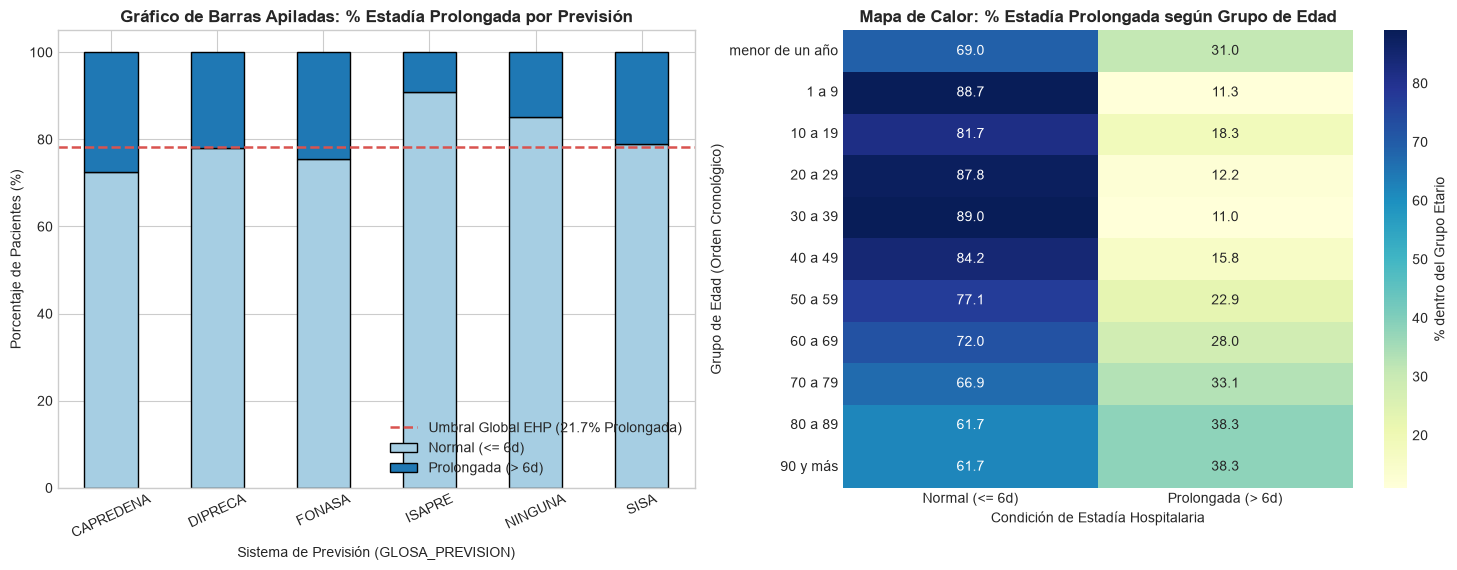

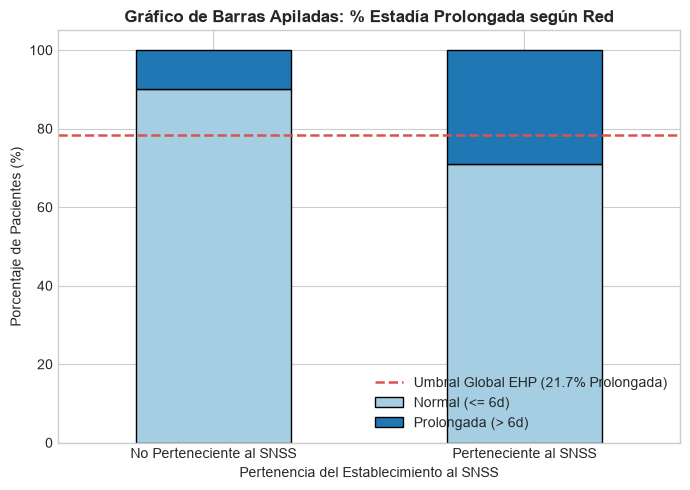

In [14]:
# ==============================================================================
# 5.4 CATEGÓRICA VS. CATEGÓRICA: CHI-CUADRADO DE INDEPENDENCIA Y V DE CRAMÉR
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

alpha = 0.05
col_estadia = "DIAS_ESTADA" if "DIAS_ESTADA" in df.columns else "DIAS_ESTAD"

# Asegurar que df_prev y df_snss estén disponibles incluso si se ejecuta esta celda directamente
if "RED_SNSS" not in df.columns:
    df["RED_SNSS"] = np.where(
        df["PERTENENCIA_ESTABLECIMIENTO_SALU"].astype(str).str.lower().str.startswith("no"),
        "No Perteneciente al SNSS",
        "Perteneciente al SNSS"
    )
conteo_prev = df["GLOSA_PREVISION"].value_counts()
df_prev = df[df["GLOSA_PREVISION"].isin(conteo_prev[conteo_prev >= 100].index)].copy()
df_snss = df.copy()

def analizar_chi2_cramer(df_in, col_x, col_y="ESTADIA_PROLONGADA", orden_filas=None):
    tabla = pd.crosstab(df_in[col_x], df_in[col_y])
    if orden_filas is not None:
        filas_validas = [f for f in orden_filas if f in tabla.index]
        tabla = tabla.loc[filas_validas]
    chi2_val, p_val, dof, expected = stats.chi2_contingency(tabla)
    n_tot = tabla.sum().sum()
    min_dim = min(tabla.shape[0] - 1, tabla.shape[1] - 1)
    cramer_v = np.sqrt(chi2_val / (n_tot * min_dim)) if min_dim > 0 else 0.0
    min_exp = expected.min()

    # Si es 2x2 y alguna frecuencia esperada < 5, calcular también Test Exacto de Fisher
    nota_supuesto = f"Cumple supuesto (E_min = {min_exp:.1f} >= 5)"
    if tabla.shape == (2, 2) and min_exp < 5:
        _, p_val = stats.fisher_exact(tabla)
        nota_supuesto = f"Se aplicó Exacto de Fisher (E_min = {min_exp:.1f} < 5)"

    print("=" * 80)
    print(f"PRUEBA CHI-CUADRADO: {col_x} vs. {col_y}")
    print("=" * 80)
    print("Tabla de Contingencia (Frecuencias Observadas):")
    display(tabla)
    print(f"Estadístico Chi² (χ²)   : {chi2_val:.4f}")
    print(f"Grados de libertad (gl) : {dof}")
    print(f"Valor-p                 : {p_val:.4e}")
    print(f"Supuesto Frec. Esperadas: {nota_supuesto}")
    print(f"V de Cramér (Asociación): {cramer_v:.4f}")
    print(f"Decisión (alpha = 0.05) : {'Rechazar H0 (Variables Asociadas)' if p_val < alpha else 'No rechazar H0 (Independientes)'}")
    return tabla, chi2_val, dof, p_val, cramer_v

# Ordenar los tramos de GRUPO_EDAD cronológicamente según EDAD_APROX
orden_edad = (
    df.groupby("GRUPO_EDAD")["EDAD_APROX"].mean().sort_values().index.tolist()
)

# Ejecutar para las 3 relaciones principales del estudio
t_edad, chi2_edad, gl_edad, p_chi_edad, v_edad = analizar_chi2_cramer(df, "GRUPO_EDAD", orden_filas=orden_edad)
t_prev, chi2_prev, gl_prev, p_chi_prev, v_prev = analizar_chi2_cramer(df_prev, "GLOSA_PREVISION")
t_snss, chi2_snss, gl_snss, p_chi_snss, v_snss = analizar_chi2_cramer(df_snss, "RED_SNSS")

# Visualización: Gráfico de Barras Apiladas al 100% y Mapa de Calor de Proporciones
tasa_global_ehp = df["ESTADIA_PROLONGADA_BIN"].mean() * 100
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.8))

# Panel A: Barras apiladas de proporción de Estadía Prolongada según Sistema de Previsión
prop_prev = pd.crosstab(df_prev["GLOSA_PREVISION"], df_prev["ESTADIA_PROLONGADA"], normalize="index") * 100
prop_prev.plot(kind="bar", stacked=True, color=["#A6CEE3", "#1F78B4"], ax=ax1, edgecolor="black")
ax1.axhline(100 - tasa_global_ehp, color="#D9534F", linestyle="--", lw=1.8,
            label=f"Umbral Global EHP ({tasa_global_ehp:.1f}% Prolongada)")
ax1.set_title("Gráfico de Barras Apiladas: % Estadía Prolongada por Previsión", fontweight="bold")
ax1.set_xlabel("Sistema de Previsión (GLOSA_PREVISION)")
ax1.set_ylabel("Porcentaje de Pacientes (%)")
ax1.tick_params(axis="x", rotation=25)
ax1.legend(loc="lower right")

# Panel B: Mapa de calor (Heatmap) de proporción de Estadía Prolongada por Grupo de Edad (orden cronológico)
prop_edad = pd.crosstab(df["GRUPO_EDAD"], df["ESTADIA_PROLONGADA"], normalize="index").loc[orden_edad] * 100
sns.heatmap(prop_edad, annot=True, fmt=".1f", cmap="YlGnBu", cbar_kws={"label": "% dentro del Grupo Etario"}, ax=ax2)
ax2.set_title("Mapa de Calor: % Estadía Prolongada según Grupo de Edad", fontweight="bold")
ax2.set_xlabel("Condición de Estadía Hospitalaria")
ax2.set_ylabel("Grupo de Edad (Orden Cronológico)")

plt.tight_layout()
plt.show()

# Gráfico de barras apiladas: % de estadía prolongada según pertenencia al SNSS
prop_snss = pd.crosstab(df["RED_SNSS"], df["ESTADIA_PROLONGADA"], normalize="index") * 100
fig, ax = plt.subplots(figsize=(7, 5))
prop_snss.plot(kind="bar", stacked=True, color=["#A6CEE3", "#1F78B4"], ax=ax, edgecolor="black")
ax.axhline(100 - tasa_global_ehp, color="#D9534F", linestyle="--", lw=1.8,
           label=f"Umbral Global EHP ({tasa_global_ehp:.1f}% Prolongada)")
ax.set_title("Gráfico de Barras Apiladas: % Estadía Prolongada según Red", fontweight="bold")
ax.set_xlabel("Pertenencia del Establecimiento al SNSS")
ax.set_ylabel("Porcentaje de Pacientes (%)")
ax.tick_params(axis="x", rotation=0)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

#### Interpretación Clínica y Metodológica (Sección 5.4)
* **Verificación de supuestos:** En las tres tablas de contingencia, todas las celdas presentan frecuencias esperadas $E_{ij} \gg 5$, cumpliéndose holgadamente la condición de validez asintótica de la prueba **Chi-cuadrado de independencia ($\chi^2$)**.
* **Decisiones e interpretación sustantiva:**
  1. **`GRUPO_EDAD` vs. `ESTADIA_PROLONGADA`:** Se rechaza $H_0$ ($p < 0.05$). El mapa de calor ordenado cronológicamente evidencia un gradiente etario claro: mientras en niños de 1 a 9 años y adultos jóvenes la proporción de estadías prolongadas ($> 6\text{ días}$) es reducida ($11\%$–$18\%$), en los tramos de adultos mayores ($\ge 60$ años) el porcentaje de episodios que superan el percentil 75 aumenta drásticamente ($28.0\%$ en 60–69 hasta $38.3\%$ en 80–89 y 90 y más). Los **menores de un año** son una excepción, con una tasa elevada ($31.0\%$). Esta variable obtiene el **V de Cramér** más alto entre las tres ($V = 0.226$, asociación pequeña), prácticamente igual al de la pertenencia al SNSS ($V = 0.226$).
  2. **`GLOSA_PREVISION` vs. `ESTADIA_PROLONGADA`:** Se rechaza $H_0$ ($p < 0.05$). El gráfico de barras apiladas muestra que los beneficiarios de **FONASA** superan la tasa global de estadías prolongadas ($24.5\%$ frente al $21.65\%$ global), aunque la tasa más alta corresponde a **CAPREDENA** ($27.5\%$, con solo $7.226$ egresos), mientras que los afiliados a **ISAPRE** presentan una proporción significativamente menor de estancias extendidas ($9.1\%$). La fuerza de asociación es pequeña ($V = 0.143$).
  3. **`PERTENENCIA_ESTABLECIMIENTO_SALU` vs. `ESTADIA_PROLONGADA`:** Se rechaza $H_0$ ($p < 0.05$). La pertenencia al **SNSS** se asocia significativamente con una mayor probabilidad de Estadía Hospitalaria Prolongada ($29.0\%$ frente a $9.9\%$ en establecimientos no pertenecientes; $V = 0.226$, asociación pequeña), respaldando empíricamente la hipótesis de trabajo del proyecto.

#### Variable de control clínico: `DIAG1` vs. `ESTADIA_PROLONGADA`

Como el modelo del Avance 2 incorpora el diagnóstico principal como variable de control, se caracteriza su relación con la estadía prolongada. Esta prueba no corresponde a una hipótesis específica adicional del estudio.

* **$H_0$:** La estadía prolongada es independiente del grupo diagnóstico.
* **$H_1$:** Existe asociación entre el grupo diagnóstico y la estadía prolongada.
* **Agrupación para esta prueba:** se usa la primera letra del código CIE-10 de `DIAG1`, porque los códigos sin agrupar no cumplen el supuesto de frecuencias esperadas $E_{ij} \ge 5$. La letra es una aproximación y no equivale exactamente a un capítulo CIE-10. La agrupación por capítulos se aplica en el modelo del Avance 2.

Códigos DIAG1 distintos               : 6,776
Celdas con frecuencia esperada < 5    : 46.3%
-> No se cumple el supuesto: la prueba se aplica sobre la primera letra del código.

PRUEBA CHI-CUADRADO: DIAG_LETRA vs. ESTADIA_PROLONGADA
Tabla de Contingencia (Frecuencias Observadas):


ESTADIA_PROLONGADA,Normal (<= 6d),Prolongada (> 6d)
DIAG_LETRA,,
A,11796,5663
B,2077,1525
C,43419,16547
D,28831,5684
E,36661,8514
F,11817,15071
G,16136,5286
H,9419,791
I,57538,35786


Estadístico Chi² (χ²)   : 80339.0474
Grados de libertad (gl) : 21
Valor-p                 : 0.0000e+00
Supuesto Frec. Esperadas: Cumple supuesto (E_min = 184.3 >= 5)
V de Cramér (Asociación): 0.2834
Decisión (alpha = 0.05) : Rechazar H0 (Variables Asociadas)


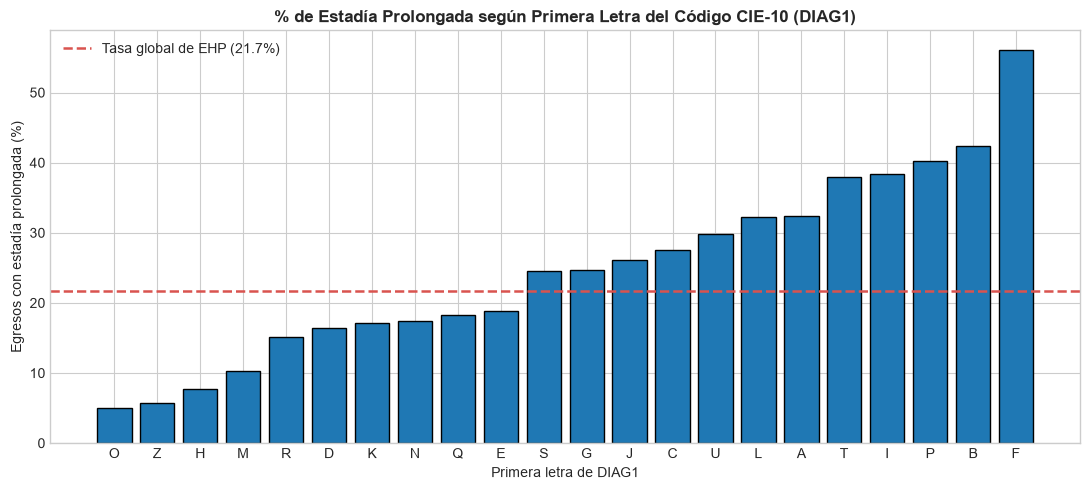

DIAG_LETRA
O     5.0
Z     5.8
H     7.7
M    10.3
R    15.1
D    16.5
K    17.1
N    17.5
Q    18.2
E    18.8
S    24.6
G    24.7
J    26.1
C    27.6
U    29.8
L    32.2
A    32.4
T    38.0
I    38.3
P    40.2
B    42.3
F    56.1
Egresos por letra (menor a mayor): {'U': 851, 'B': 3602, 'Q': 9458}


In [15]:
# ==============================================================================
# 5.4 VARIABLE DE CONTROL CLÍNICO: PRIMERA LETRA DE DIAG1 VS. ESTADIA_PROLONGADA
# ==============================================================================
# Comprobación del supuesto con los códigos sin agrupar
tabla_codigos = pd.crosstab(df["DIAG1"], df["ESTADIA_PROLONGADA"])
_, _, _, esperadas_codigos = stats.chi2_contingency(tabla_codigos)
print(f"Códigos DIAG1 distintos               : {tabla_codigos.shape[0]:,}")
print(f"Celdas con frecuencia esperada < 5    : {(esperadas_codigos < 5).mean() * 100:.1f}%")
print("-> No se cumple el supuesto: la prueba se aplica sobre la primera letra del código.\n")

df["DIAG_LETRA"] = df["DIAG1"].astype(str).str[0]
t_diag, chi2_diag, gl_diag, p_chi_diag, v_diag = analizar_chi2_cramer(df, "DIAG_LETRA")

# Visualización: tasa de estadía prolongada por letra del código
tasa_diag = df.groupby("DIAG_LETRA")["ESTADIA_PROLONGADA_BIN"].mean().mul(100).sort_values()
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(tasa_diag.index, tasa_diag.values, color="#1F78B4", edgecolor="black")
ax.axhline(tasa_global_ehp, color="#D9534F", linestyle="--", lw=1.8,
           label=f"Tasa global de EHP ({tasa_global_ehp:.1f}%)")
ax.set_title("% de Estadía Prolongada según Primera Letra del Código CIE-10 (DIAG1)", fontweight="bold")
ax.set_xlabel("Primera letra de DIAG1")
ax.set_ylabel("Egresos con estadía prolongada (%)")
ax.legend()
plt.tight_layout()
plt.show()
print(tasa_diag.round(1).to_string())
print("Egresos por letra (menor a mayor):", t_diag.sum(axis=1).sort_values().head(3).to_dict())

#### Interpretación: `DIAG1` vs. `ESTADIA_PROLONGADA`
* **Verificación de supuestos:** con los 6.776 códigos sin agrupar, el $46.3\%$ de las celdas tiene una frecuencia esperada menor que 5, por lo que no se cumple el supuesto. Con la primera letra del código (22 categorías) se cumple ($E_{\min} = 184.3$).
* **Decisión estadística:** se rechaza $H_0$ ($\chi^2 = 80339.05$, $gl = 21$, $p < 0.05$). La fuerza de asociación es $V = 0.283$.
* **Interpretación:** la tasa de estadía prolongada varía de forma marcada según el diagnóstico: va de $5.0\%$ en la letra O (embarazo, parto y puerperio) a $56.1\%$ en la letra F (trastornos mentales y del comportamiento). La asociación es mayor que la de edad y red ($V = 0.226$ en ambas), lo que respalda controlar por el diagnóstico en el Avance 2. Como se registra al egreso, este resultado describe el perfil del egreso y no una predicción al ingreso.
* **Precaución:** algunas letras tienen pocos egresos (por ejemplo, U tiene 851), por lo que sus tasas son menos estables.

#### Variable de control demográfico: `SEXO`

Como el modelo del Avance 2 incluye el sexo como variable de control, se caracteriza su relación con la duración de la estadía y con la estadía prolongada. Esta prueba no corresponde a una hipótesis específica adicional del estudio. Se excluyen los 9 egresos con sexo indeterminado, insuficientes para estimar su efecto.

* **`SEXO` vs. `DIAS_ESTADA`:** sean $X_H$ y $X_M$ las estadías de un hombre y de una mujer elegidos al azar. $H_0$: $P(X_H > X_M) = P(X_M > X_H)$, es decir, ninguno de los dos sexos tiende a tener estadías más largas. $H_1$: $P(X_H > X_M) \neq P(X_M > X_H)$. Por el rechazo de normalidad, se aplica **Mann–Whitney U**, junto con Levene para comparar la dispersión ($\alpha = 0.05$).
* **`SEXO` vs. `ESTADIA_PROLONGADA`:** $H_0$: la estadía prolongada es independiente del sexo. $H_1$: existe asociación entre ambas variables. Se aplica **Chi-cuadrado de independencia** con **V de Cramér** ($\alpha = 0.05$).

RESULTADOS: DOS GRUPOS (DIAS_ESTADA por SEXO), excluidos 9 egresos con sexo indeterminado
Hombres (n=429,425, Media=7.33, Mediana=3.0)
Mujeres (n=570,566, Media=5.23, Mediana=2.0)
--------------------------------------------------------------------------------
1) Prueba de Levene (Varianzas) : W = 681.6179 | valor-p = 3.3393e-150
2) Mann-Whitney U               : U = 1.2953e+11 | valor-p = 0.0000e+00 | Decisión: Rechazar H0
   Tamaño del efecto            : r_rb = 0.057 | Prob. de superioridad = 0.529

PRUEBA CHI-CUADRADO: SEXO vs. ESTADIA_PROLONGADA
Tabla de Contingencia (Frecuencias Observadas):


ESTADIA_PROLONGADA,Normal (<= 6d),Prolongada (> 6d)
SEXO,,
HOMBRE,318019,111406
MUJER,465428,105138


Estadístico Chi² (χ²)   : 8158.2085
Grados de libertad (gl) : 1
Valor-p                 : 0.0000e+00
Supuesto Frec. Esperadas: Cumple supuesto (E_min = 92990.2 >= 5)
V de Cramér (Asociación): 0.0903
Decisión (alpha = 0.05) : Rechazar H0 (Variables Asociadas)


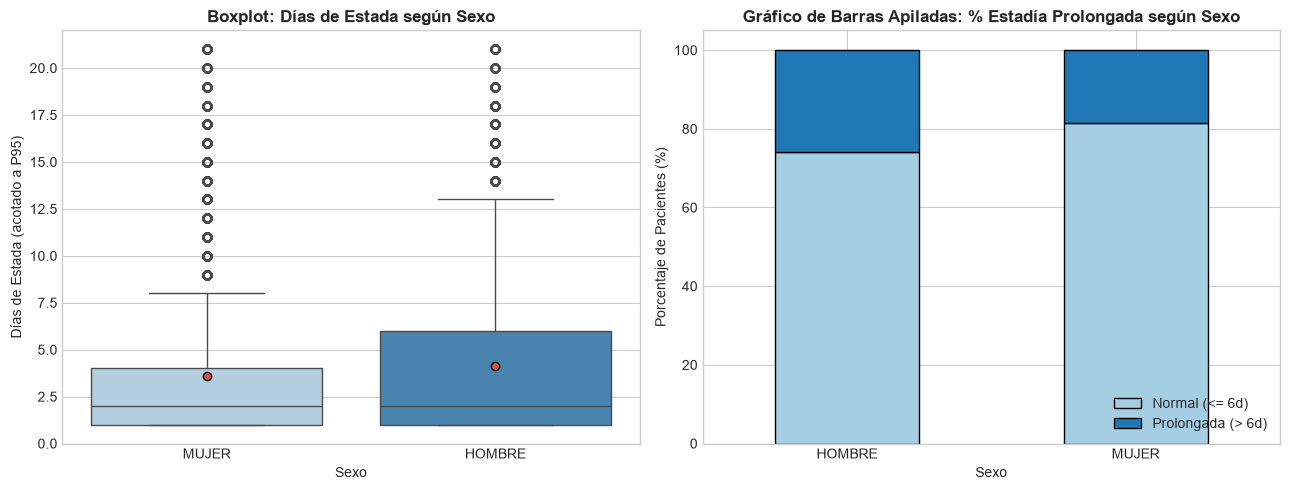

ESTADIA_PROLONGADA  Normal (<= 6d)  Prolongada (> 6d)
SEXO                                                 
HOMBRE                        74.1               25.9
MUJER                         81.6               18.4


In [16]:
# ==============================================================================
# 5.3 Y 5.4 VARIABLE DE CONTROL DEMOGRÁFICO: SEXO VS. DIAS_ESTADA Y ESTADIA_PROLONGADA
# ==============================================================================
df_sexo = df[df["SEXO"].isin(["HOMBRE", "MUJER"])].copy()
g_hombre = df_sexo.loc[df_sexo["SEXO"] == "HOMBRE", col_estadia].to_numpy()
g_mujer = df_sexo.loc[df_sexo["SEXO"] == "MUJER", col_estadia].to_numpy()

stat_lev_sexo, p_lev_sexo = stats.levene(g_hombre, g_mujer, center="median")
stat_mwu_sexo, p_mwu_sexo = stats.mannwhitneyu(g_hombre, g_mujer, alternative="two-sided")
prob_sup_sexo = stat_mwu_sexo / (len(g_hombre) * len(g_mujer))
r_rb_sexo = 2 * prob_sup_sexo - 1

print("=" * 80)
print(f"RESULTADOS: DOS GRUPOS ({col_estadia} por SEXO), excluidos {len(df) - len(df_sexo)} egresos con sexo indeterminado")
print(f"Hombres (n={len(g_hombre):,}, Media={g_hombre.mean():.2f}, Mediana={np.median(g_hombre):.1f})")
print(f"Mujeres (n={len(g_mujer):,}, Media={g_mujer.mean():.2f}, Mediana={np.median(g_mujer):.1f})")
print("-" * 80)
print(f"1) Prueba de Levene (Varianzas) : W = {stat_lev_sexo:.4f} | valor-p = {p_lev_sexo:.4e}")
print(f"2) Mann-Whitney U               : U = {stat_mwu_sexo:.4e} | valor-p = {p_mwu_sexo:.4e} | "
      f"Decisión: {'Rechazar H0' if p_mwu_sexo < alpha else 'No rechazar H0'}")
print(f"   Tamaño del efecto            : r_rb = {r_rb_sexo:.3f} | Prob. de superioridad = {prob_sup_sexo:.3f}\n")

t_sexo, chi2_sexo, gl_sexo, p_chi_sexo, v_sexo = analizar_chi2_cramer(df_sexo, "SEXO")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
muestra_box_sexo = df_sexo[df_sexo[col_estadia] <= p95_box].sample(n=50000, random_state=42)
sns.boxplot(data=muestra_box_sexo, x="SEXO", y=col_estadia, hue="SEXO", legend=False, palette="Blues", ax=ax1, showmeans=True,
            meanprops={"marker": "o", "markerfacecolor": "#D9534F", "markeredgecolor": "black"})
ax1.set_title("Boxplot: Días de Estada según Sexo", fontweight="bold")
ax1.set_xlabel("Sexo"); ax1.set_ylabel("Días de Estada (acotado a P95)")
prop_sexo = pd.crosstab(df_sexo["SEXO"], df_sexo["ESTADIA_PROLONGADA"], normalize="index") * 100
prop_sexo.plot(kind="bar", stacked=True, color=["#A6CEE3", "#1F78B4"], ax=ax2, edgecolor="black")
ax2.set_title("Gráfico de Barras Apiladas: % Estadía Prolongada según Sexo", fontweight="bold")
ax2.set_xlabel("Sexo"); ax2.set_ylabel("Porcentaje de Pacientes (%)")
ax2.tick_params(axis="x", rotation=0); ax2.legend(loc="lower right")
plt.tight_layout()
plt.show()
print(prop_sexo.round(1).to_string())

#### Interpretación: `SEXO`
* **Verificación de supuestos:** se rechaza la igualdad de varianzas (Levene, $W = 681.62$, $p < 0.001$), por lo que las distribuciones no tienen la misma forma y Mann–Whitney U se interpreta como tendencia a estadías más largas, no como diferencia de medianas. En la tabla de contingencia, todas las frecuencias esperadas superan 5 ($E_{\min} = 92990.2$).
* **`SEXO` vs. `DIAS_ESTADA`:** se rechaza $H_0$ (Mann–Whitney, $U = 1.30 \times 10^{11}$, $p < 0.001$). Los hombres registran estadías más largas (media de $7.33$ días y mediana de $3$) que las mujeres (media de $5.23$ días y mediana de $2$), pero el efecto es muy pequeño ($r_{rb} = 0.057$).
* **`SEXO` vs. `ESTADIA_PROLONGADA`:** se rechaza $H_0$ ($\chi^2 = 8158.21$, $gl = 1$, $p < 0.001$). Los hombres presentan una mayor proporción de estadías prolongadas ($25.9\%$ frente a $18.4\%$), con una asociación muy pequeña ($V = 0.090$).
* **Interpretación:** el sexo muestra una asociación significativa, pero de poca magnitud. Se incluye en el modelo como variable de control, sin hipótesis específica propia.

---
### 5.5 Tabla Resumen de Pruebas Estadísticas
La siguiente celda consolida en una tabla resumen todas las pruebas de hipótesis ejecutadas en las subsecciones **5.1 a 5.4**, especificando **Variable 1**, **Variable 2**, **Test aplicado** (con justificación de sus supuestos), **Valor-$p$**, **Tamaño del efecto** y **Conclusión en el contexto del problema hospitalario**. Las cinco columnas que exige la pauta se complementan con la del tamaño del efecto, que indica la magnitud de cada relación según la guía de la sección 5 ($r_{rb}$, $\rho$ y $V$: pequeño desde $0.1$, moderado desde $0.3$ y grande desde $0.5$; $\varepsilon^2$: pequeño desde $0.01$, moderado desde $0.06$ y grande desde $0.14$). Los estadísticos de cada prueba se reportan en su subsección.

In [17]:
# ==============================================================================
# 5.5 CONSTRUCCIÓN AUTOMÁTICA DE LA TABLA RESUMEN
# ==============================================================================
import pandas as pd

def fmt_p(p):
    return "< 0.001" if p < 0.001 else f"{p:.3f}"

# Magnitud según la guía de la sección 5: r_rb, rho y V (0.1 / 0.3 / 0.5); ε² (0.01 / 0.06 / 0.14)
def magnitud(valor, cortes=(0.1, 0.3, 0.5)):
    v = abs(valor)
    if v < cortes[0]:
        return "muy pequeño"
    elif v < cortes[1]:
        return "pequeño"
    elif v < cortes[2]:
        return "moderado"
    return "grande"

def efecto(nombre, valor, cortes=(0.1, 0.3, 0.5)):
    return f"{nombre} = {valor:.3f} ({magnitud(valor, cortes)})"

CORTES_EPS2 = (0.01, 0.06, 0.14)

filas_resumen = [
    {
        "Variable 1": "DIAS_ESTADA (Numérica)",
        "Variable 2": "Distribución Normal Teórica",
        "Test aplicado": "Shapiro-Wilk / Lilliefors (K-S) / Anderson-Darling (submuestra n = 5.000)",
        "Valor-p": fmt_p(p_sw),
        "Tamaño del efecto": "No aplica (prueba de normalidad)",
        "Conclusión": "Se rechaza H0 (p < 0.05). Los días de estada presentan fuerte asimetría positiva (198.13); corresponde aplicar pruebas no paramétricas."
    },
    {
        "Variable 1": "GRUPO_EDAD (orden de los tramos)",
        "Variable 2": "DIAS_ESTADA (Numérica)",
        "Test aplicado": "Correlación de Spearman sobre el orden de GRUPO_EDAD",
        "Valor-p": fmt_p(p_spearman),
        "Tamaño del efecto": efecto("ρ", rho_spearman),
        "Conclusión": "Se rechaza H0 (p < 0.05). Existe una tendencia positiva global entre la edad y la duración de la hospitalización, de magnitud pequeña, con la excepción de los menores de un año, que registran la media más alta."
    },
    {
        "Variable 1": "PERTENENCIA_ESTABLECIMIENTO_SALU (Categórica, 2 grupos)",
        "Variable 2": "DIAS_ESTADA (Numérica)",
        "Test aplicado": "Mann-Whitney U (por no normalidad; Levene p < 0.05)",
        "Valor-p": fmt_p(p_mwu),
        "Tamaño del efecto": efecto("r_rb", r_rb_snss),
        "Conclusión": "Se rechaza H0 (p < 0.05). Los hospitales pertenecientes al SNSS registran estadías significativamente mayores que los no pertenecientes, con un efecto moderado."
    },
    {
        "Variable 1": "GLOSA_PREVISION (Categórica, >= 3 grupos)",
        "Variable 2": "DIAS_ESTADA (Numérica)",
        "Test aplicado": "Kruskal-Wallis (por no normalidad) + Post-hoc de Dunn (Bonferroni)",
        "Valor-p": fmt_p(p_kw_prev),
        "Tamaño del efecto": efecto("ε²", eps2_prev, CORTES_EPS2),
        "Conclusión": "Se rechaza H0 (p < 0.05). Hay diferencias significativas por previsión (Dunn: los 15 pares difieren), con un efecto global pequeño; pacientes FONASA presentan mayor duración de estadía que ISAPRE."
    },
    {
        "Variable 1": "GRUPO_EDAD (Categórica, >= 3 grupos)",
        "Variable 2": "DIAS_ESTADA (Numérica)",
        "Test aplicado": "Kruskal-Wallis (por no normalidad) + Post-hoc de Dunn (Bonferroni)",
        "Valor-p": fmt_p(p_kw_edad),
        "Tamaño del efecto": efecto("ε²", eps2_edad, CORTES_EPS2),
        "Conclusión": "Se rechaza H0 (p < 0.05). Según Dunn, los tramos de 60 años y más tienen estadías significativamente más largas que los de 1 a 59 años; los menores de un año superan a los de 60 a 79 años. El efecto global es moderado."
    },
    {
        "Variable 1": "SEXO (Categórica, 2 grupos, variable de control)",
        "Variable 2": "DIAS_ESTADA (Numérica)",
        "Test aplicado": "Mann-Whitney U (por no normalidad)",
        "Valor-p": fmt_p(p_mwu_sexo),
        "Tamaño del efecto": efecto("r_rb", r_rb_sexo),
        "Conclusión": "Se rechaza H0 (p < 0.05). Los hombres registran estadías más largas que las mujeres, pero el efecto es muy pequeño; se incluye como control en el modelo."
    },
    {
        "Variable 1": "GRUPO_EDAD (Categórica)",
        "Variable 2": "ESTADIA_PROLONGADA (Categórica Binaria > P75)",
        "Test aplicado": "Chi-cuadrado de Independencia (χ²) + V de Cramér",
        "Valor-p": fmt_p(p_chi_edad),
        "Tamaño del efecto": efecto("V de Cramér", v_edad),
        "Conclusión": "Se rechaza H0 (p < 0.05). El grupo etario se asocia significativamente con la probabilidad de presentar Estadía Hospitalaria Prolongada."
    },
    {
        "Variable 1": "GLOSA_PREVISION (Categórica)",
        "Variable 2": "ESTADIA_PROLONGADA (Categórica Binaria > P75)",
        "Test aplicado": "Chi-cuadrado de Independencia (χ²) + V de Cramér",
        "Valor-p": fmt_p(p_chi_prev),
        "Tamaño del efecto": efecto("V de Cramér", v_prev),
        "Conclusión": "Se rechaza H0 (p < 0.05). El sistema previsional se asocia significativamente con la incidencia de Estadía Hospitalaria Prolongada, con una fuerza pequeña."
    },
    {
        "Variable 1": "PERTENENCIA_ESTABLECIMIENTO_SALU (Categórica)",
        "Variable 2": "ESTADIA_PROLONGADA (Categórica Binaria > P75)",
        "Test aplicado": "Chi-cuadrado de Independencia (χ²) + V de Cramér",
        "Valor-p": fmt_p(p_chi_snss),
        "Tamaño del efecto": efecto("V de Cramér", v_snss),
        "Conclusión": "Se rechaza H0 (p < 0.05). La pertenencia del hospital a la red pública SNSS se asocia con mayor proporción de Estadías Prolongadas."
    },
    {
        "Variable 1": "SEXO (Categórica, variable de control)",
        "Variable 2": "ESTADIA_PROLONGADA (Categórica Binaria > P75)",
        "Test aplicado": "Chi-cuadrado de Independencia (χ²) + V de Cramér",
        "Valor-p": fmt_p(p_chi_sexo),
        "Tamaño del efecto": efecto("V de Cramér", v_sexo),
        "Conclusión": "Se rechaza H0 (p < 0.05). Los hombres presentan mayor proporción de Estadía Prolongada (25.9% frente a 18.4%), con una asociación muy pequeña; se incluye como control en el modelo."
    },
    {
        "Variable 1": "DIAG1, primera letra (Categórica, variable de control)",
        "Variable 2": "ESTADIA_PROLONGADA (Categórica Binaria > P75)",
        "Test aplicado": "Chi-cuadrado de Independencia (χ²) + V de Cramér",
        "Valor-p": fmt_p(p_chi_diag),
        "Tamaño del efecto": efecto("V de Cramér", v_diag),
        "Conclusión": "Se rechaza H0 (p < 0.05). La tasa de Estadía Prolongada varía según el grupo diagnóstico aproximado; se justifica incluir el diagnóstico como control en el modelo."
    }
]

tabla_resumen_55 = pd.DataFrame(filas_resumen)
pd.set_option("display.max_colwidth", None)
display(tabla_resumen_55)

,Variable 1,Variable 2,Test aplicado,Valor-p,Tamaño del efecto,Conclusión
0,DIAS_ESTADA (Numérica),Distribución Normal Teórica,Shapiro-Wilk / Lilliefors (K-S) / Anderson-Darling (submuestra n = 5.000),< 0.001,No aplica (prueba de normalidad),Se rechaza H0 (p < 0.05). Los días de estada presentan fuerte asimetría positiva (198.13); corresponde aplicar pruebas no paramétricas.
1,GRUPO_EDAD (orden de los tramos),DIAS_ESTADA (Numérica),Correlación de Spearman sobre el orden de GRUPO_EDAD,< 0.001,ρ = 0.191 (pequeño),"Se rechaza H0 (p < 0.05). Existe una tendencia positiva global entre la edad y la duración de la hospitalización, de magnitud pequeña, con la excepción de los menores de un año, que registran la media más alta."
2,"PERTENENCIA_ESTABLECIMIENTO_SALU (Categórica, 2 grupos)",DIAS_ESTADA (Numérica),Mann-Whitney U (por no normalidad; Levene p < 0.05),< 0.001,r_rb = 0.425 (moderado),"Se rechaza H0 (p < 0.05). Los hospitales pertenecientes al SNSS registran estadías significativamente mayores que los no pertenecientes, con un efecto moderado."
3,"GLOSA_PREVISION (Categórica, >= 3 grupos)",DIAS_ESTADA (Numérica),Kruskal-Wallis (por no normalidad) + Post-hoc de Dunn (Bonferroni),< 0.001,ε² = 0.048 (pequeño),"Se rechaza H0 (p < 0.05). Hay diferencias significativas por previsión (Dunn: los 15 pares difieren), con un efecto global pequeño; pacientes FONASA presentan mayor duración de estadía que ISAPRE."
4,"GRUPO_EDAD (Categórica, >= 3 grupos)",DIAS_ESTADA (Numérica),Kruskal-Wallis (por no normalidad) + Post-hoc de Dunn (Bonferroni),< 0.001,ε² = 0.062 (moderado),"Se rechaza H0 (p < 0.05). Según Dunn, los tramos de 60 años y más tienen estadías significativamente más largas que los de 1 a 59 años; los menores de un año superan a los de 60 a 79 años. El efecto global es moderado."
5,"SEXO (Categórica, 2 grupos, variable de control)",DIAS_ESTADA (Numérica),Mann-Whitney U (por no normalidad),< 0.001,r_rb = 0.057 (muy pequeño),"Se rechaza H0 (p < 0.05). Los hombres registran estadías más largas que las mujeres, pero el efecto es muy pequeño; se incluye como control en el modelo."
6,GRUPO_EDAD (Categórica),ESTADIA_PROLONGADA (Categórica Binaria > P75),Chi-cuadrado de Independencia (χ²) + V de Cramér,< 0.001,V de Cramér = 0.226 (pequeño),Se rechaza H0 (p < 0.05). El grupo etario se asocia significativamente con la probabilidad de presentar Estadía Hospitalaria Prolongada.
7,GLOSA_PREVISION (Categórica),ESTADIA_PROLONGADA (Categórica Binaria > P75),Chi-cuadrado de Independencia (χ²) + V de Cramér,< 0.001,V de Cramér = 0.143 (pequeño),"Se rechaza H0 (p < 0.05). El sistema previsional se asocia significativamente con la incidencia de Estadía Hospitalaria Prolongada, con una fuerza pequeña."
8,PERTENENCIA_ESTABLECIMIENTO_SALU (Categórica),ESTADIA_PROLONGADA (Categórica Binaria > P75),Chi-cuadrado de Independencia (χ²) + V de Cramér,< 0.001,V de Cramér = 0.226 (pequeño),Se rechaza H0 (p < 0.05). La pertenencia del hospital a la red pública SNSS se asocia con mayor proporción de Estadías Prolongadas.
9,"SEXO (Categórica, variable de control)",ESTADIA_PROLONGADA (Categórica Binaria > P75),Chi-cuadrado de Independencia (χ²) + V de Cramér,< 0.001,V de Cramér = 0.090 (muy pequeño),"Se rechaza H0 (p < 0.05). Los hombres presentan mayor proporción de Estadía Prolongada (25.9% frente a 18.4%), con una asociación muy pequeña; se incluye como control en el modelo."



---
### Síntesis Global del Avance 1 y Paso al Avance 2
Los contrastes de hipótesis ejecutados en esta etapa muestran que tanto los factores biodemográficos (`GRUPO_EDAD`), como los determinantes institucionales (`GLOSA_PREVISION`) y de gestión de red (`PERTENENCIA_ESTABLECIMIENTO_SALU`) mantienen relaciones estadísticamente significativas con la duración de la internación (`DIAS_ESTADA`) y con la probabilidad de incurrir en una **Estadía Hospitalaria Prolongada ($> 6\text{ días}$)**. Por tamaño del efecto, la relación con los días de estada es moderada para la red ($r_{rb} = 0.425$) y la edad ($\varepsilon^2 = 0.062$), y pequeña para la previsión ($\varepsilon^2 = 0.048$). Con la estadía prolongada, las asociaciones son pequeñas (edad y red, $V = 0.226$; previsión, $V = 0.143$). Esto respalda su inclusión conjunta como covariables en el ajuste del modelo de **Regresión Logística** durante el **Avance 2**; en el modelo, la edad se incluye como `GRUPO_EDAD`. El diagnóstico principal, usado como variable de control, también se asocia con la estadía prolongada ($V = 0.283$, con la primera letra del código CIE-10), y el sexo, usado como control demográfico, muestra una asociación muy pequeña ($V = 0.090$).